In [50]:
# Install required packages
!pip install yfinance statsmodels scipy numpy pandas matplotlib seaborn pymc arviz scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import yfinance as yf
from statsmodels.tsa.stattools import adfuller, coint
import pymc as pm
import arviz as az
import warnings
warnings.filterwarnings('ignore')

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 6)
np.random.seed(42)

print("✓ All libraries imported successfully")
print(f"PyMC version: {pm.__version__}")
print(f"ArviZ version: {az.__version__}")

✓ All libraries imported successfully
PyMC version: 5.28.5
ArviZ version: 0.22.0


In [51]:
import yfinance as yf
import pandas as pd
from datetime import datetime, timedelta

pairs = [
    ('AAPL', 'MSFT'),
    ('JPM', 'BAC'),
    ('GLD', 'SLV'),
    ('KO', 'PEP'),       # Coca-Cola vs Pepsi (beverages) ← BEST
    ('GS', 'MS'),        # Goldman Sachs vs Morgan Stanley (banks)
    ('XOM', 'CVX'),      # Exxon vs Chevron (oil)
    ('JNJ', 'PFE'),      # J&J vs Pfizer (pharma)
    ('BA', 'RTX'),       # Boeing vs Raytheon (defense)
    ('MCD', 'CMG'),      # McDonald's vs Chipotle (restaurants)
    ('XLU', 'XLE'),      # Utilities vs Energy
    ('XLV', 'XLY'),      # Healthcare vs Consumer Discretionary
    ('IVV', 'VOO'),      # S&P 500 ETFs (almost perfect correlation)
    ('EEM', 'VWO'),      # Emerging markets ETFs
]

end_date = datetime.now()
start_date = end_date - timedelta(days=int(365 * 3.5))

print(f"Downloading data from {start_date.date()} to {end_date.date()}")
print("=" * 70)

all_data = {}


def get_price(ticker, start_date, end_date):
    """
    Download data for one ticker and return a clean Series of prices.
    """

    df = yf.download(
        ticker,
        start=start_date,
        end=end_date,
        progress=False,
        auto_adjust=False
    )

    if df.empty:
        raise ValueError(f"No data downloaded for {ticker}")

    print(f"    Raw columns: {df.columns.tolist()}")

    # ---------------------------------------------------------
    # Case 1: MultiIndex columns
    # Example:
    # ('Adj Close', 'AAPL')
    # ('Close', 'AAPL')
    # ---------------------------------------------------------
    if isinstance(df.columns, pd.MultiIndex):

        # Prefer Adjusted Close
        if 'Adj Close' in df.columns.get_level_values(0):
            price = df['Adj Close']

        # Otherwise use Close
        elif 'Close' in df.columns.get_level_values(0):
            price = df['Close']

        else:
            raise ValueError(
                f"No 'Adj Close' or 'Close' column found for {ticker}. "
                f"Columns: {df.columns.tolist()}"
            )

        # Since only one ticker was downloaded, this may still
        # be a one-column DataFrame. Convert it to Series.
        if isinstance(price, pd.DataFrame):
            price = price.iloc[:, 0]

    # ---------------------------------------------------------
    # Case 2: Normal single-level columns
    # ---------------------------------------------------------
    else:

        if 'Adj Close' in df.columns:
            price = df['Adj Close']

        elif 'Close' in df.columns:
            price = df['Close']

        else:
            raise ValueError(
                f"No 'Adj Close' or 'Close' column found for {ticker}. "
                f"Columns: {df.columns.tolist()}"
            )

    # Make sure we actually have a Series
    if isinstance(price, pd.DataFrame):
        price = price.iloc[:, 0]

    price.name = ticker

    return price


# =============================================================
# DOWNLOAD ALL PAIRS
# =============================================================

for stock1, stock2 in pairs:

    print(f"\nDownloading {stock1} and {stock2}...")

    try:

        # -----------------------------------------------------
        # Download stock 1
        # -----------------------------------------------------
        print(f"  Fetching {stock1}...")

        price1 = get_price(
            stock1,
            start_date,
            end_date
        )

        print(f"    ✓ {stock1}: {len(price1)} observations")

        # -----------------------------------------------------
        # Download stock 2
        # -----------------------------------------------------
        print(f"  Fetching {stock2}...")

        price2 = get_price(
            stock2,
            start_date,
            end_date
        )

        print(f"    ✓ {stock2}: {len(price2)} observations")

        # -----------------------------------------------------
        # Combine
        # -----------------------------------------------------
        data = pd.concat(
            [price1, price2],
            axis=1
        )

        data.columns = [stock1, stock2]

        print(f"\n  Combined shape: {data.shape}")

        print("  Data types:")
        print(data.dtypes)

        # -----------------------------------------------------
        # Missing values
        # -----------------------------------------------------
        initial_nulls = data.isnull().sum()

        print(
            f"  Missing values before cleaning: "
            f"{initial_nulls.to_dict()}"
        )

        # Forward fill, then backward fill
        data = data.ffill().bfill()

        # Remove any remaining NaN
        data = data.dropna()

        print(f"  After cleaning: {data.shape}")

        # -----------------------------------------------------
        # Verify
        # -----------------------------------------------------
        if len(data) == 0:
            print("  ✗ No data after cleaning")
            continue

        # -----------------------------------------------------
        # Store
        # -----------------------------------------------------
        pair_name = f"{stock1}_{stock2}"

        all_data[pair_name] = data

        print(f"  ✓ {pair_name} stored successfully")

    except Exception as e:

        print(
            f"  ✗ Error downloading "
            f"{stock1}/{stock2}: "
            f"{type(e).__name__}: {e}"
        )

        import traceback
        traceback.print_exc()

        continue


# =============================================================
# SUMMARY
# =============================================================

print("\n" + "=" * 70)

print(
    f"✓ Downloaded "
    f"{len(all_data)} pairs successfully"
)

if len(all_data) > 0:

    print(
        f"Pairs available: "
        f"{list(all_data.keys())}"
    )

    # Get first pair
    first_pair = list(all_data.keys())[0]

    data = all_data[first_pair]

    print(f"\nFirst pair: {first_pair}")

    print(f"Shape: {data.shape}")

    print(
        f"Date range: "
        f"{data.index[0].date()} "
        f"to "
        f"{data.index[-1].date()}"
    )

    print("\nFirst 5 rows:")
    print(data.head())

    print("\nLast 5 rows:")
    print(data.tail())

else:

    print(
        "⚠️ No pairs downloaded - "
        "checking yfinance..."
    )

    # ---------------------------------------------------------
    # Test single download
    # ---------------------------------------------------------
    print("\nTesting basic yfinance download...")

    try:

        test = yf.download(
            'AAPL',
            start='2023-01-01',
            end='2023-12-31',
            progress=False,
            auto_adjust=False
        )

        print(
            f"Test download columns: "
            f"{test.columns.tolist()}"
        )

        print(
            f"Test download shape: "
            f"{test.shape}"
        )

        print("\nTest download:")
        print(test.head())

    except Exception as e:

        print(
            f"Test failed: "
            f"{type(e).__name__}: {e}"
        )


  Fetching AAPL...
    Raw columns: [('Adj Close', 'AAPL'), ('Close', 'AAPL'), ('High', 'AAPL'), ('Low', 'AAPL'), ('Open', 'AAPL'), ('Volume', 'AAPL')]
    ✓ AAPL: 877 observations
  Fetching MSFT...
    Raw columns: [('Adj Close', 'MSFT'), ('Close', 'MSFT'), ('High', 'MSFT'), ('Low', 'MSFT'), ('Open', 'MSFT'), ('Volume', 'MSFT')]
    ✓ MSFT: 877 observations

  Combined shape: (877, 2)
  Data types:
AAPL    float64
MSFT    float64
dtype: object
  Missing values before cleaning: {'AAPL': 0, 'MSFT': 0}
  After cleaning: (877, 2)
  ✓ AAPL_MSFT stored successfully

  Fetching JPM...
    Raw columns: [('Adj Close', 'JPM'), ('Close', 'JPM'), ('High', 'JPM'), ('Low', 'JPM'), ('Open', 'JPM'), ('Volume', 'JPM')]
    ✓ JPM: 877 observations
  Fetching BAC...
    Raw columns: [('Adj Close', 'BAC'), ('Close', 'BAC'), ('High', 'BAC'), ('Low', 'BAC'), ('Open', 'BAC'), ('Volume', 'BAC')]
    ✓ BAC: 877 observations

  Combined shape: (877, 2)
  Data types:
JPM    float64
BAC    float64
dtype: objec

Exploring AAPL_MSFT

Data shape: (877, 2)

First 5 rows:
                  AAPL        MSFT
Date                              
2023-03-15  150.536652  258.252716
2023-03-16  153.350754  268.721436
2023-03-17  152.514359  271.863861
2023-03-20  154.875900  264.858887
2023-03-21  156.725769  266.366882

Basic statistics:
             AAPL        MSFT
count  877.000000  877.000000
mean   222.122874  407.286277
std     43.993333   62.263501
min    150.536652  258.252716
25%    185.145859  369.542450
50%    218.859192  407.938904
75%    253.748550  445.773468
max    339.786926  537.646362

Spread Statistics:
  Mean: -0.613028
  Std: 0.158183
  Min: -0.963518
  Max: -0.135414
  Autocorr(1): 0.9932
  Autocorr(5): 0.9566


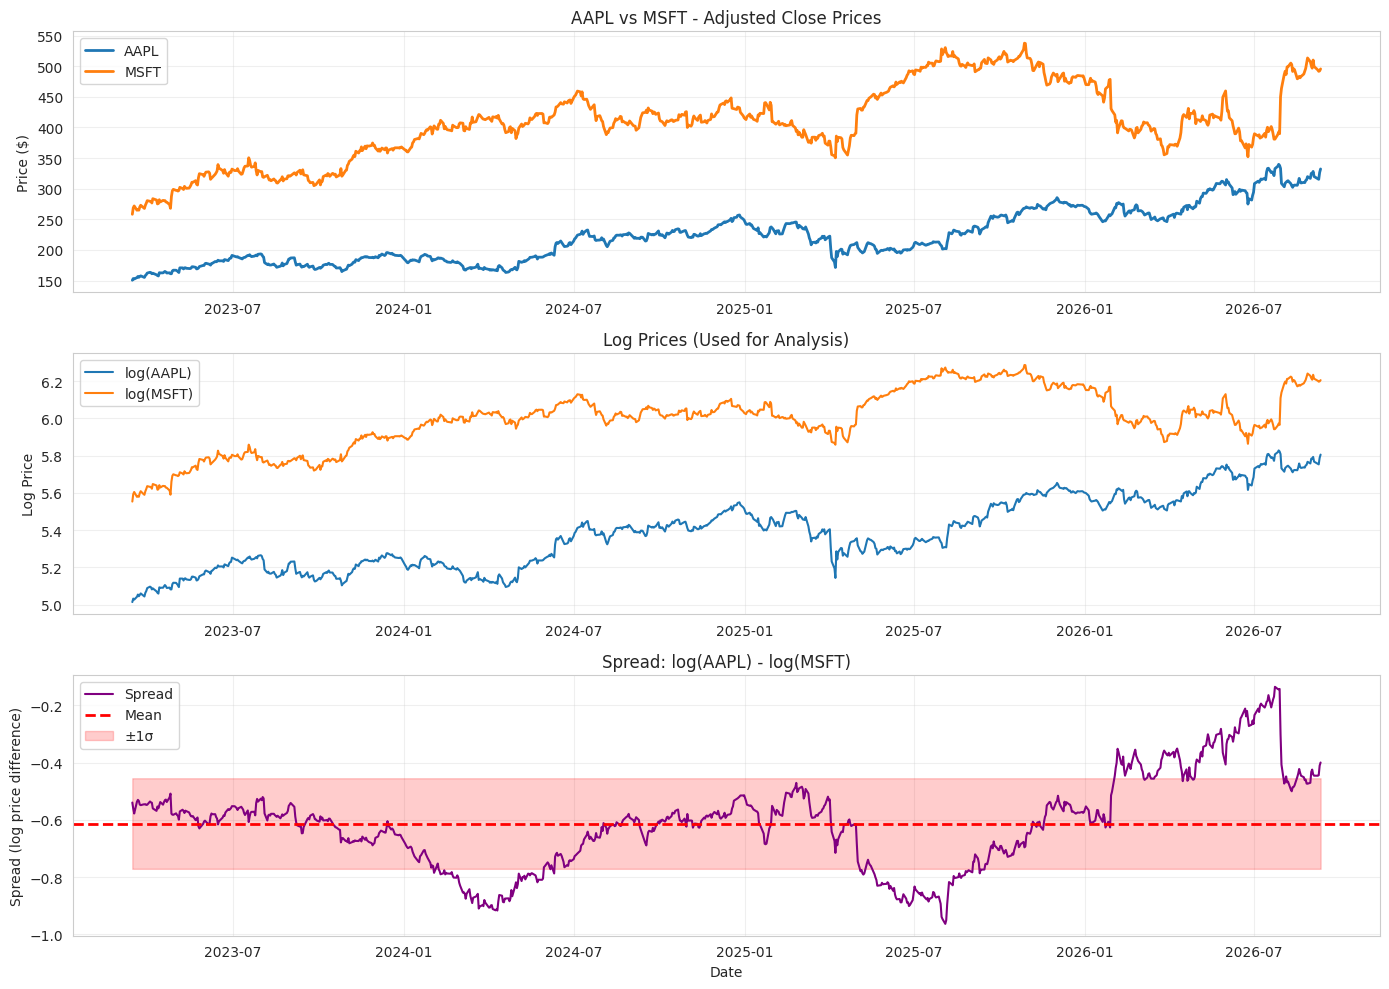


✓ Plot saved as '01_price_exploration_AAPL_MSFT.png'
Exploring JPM_BAC

Data shape: (877, 2)

First 5 rows:
                   JPM        BAC
Date                             
2023-03-15  118.320778  26.086615
2023-03-16  120.617805  26.526121
2023-03-17  116.060631  25.473137
2023-03-20  117.287567  25.409042
2023-03-21  120.433296  26.178179

Basic statistics:
              JPM         BAC
count  877.000000  877.000000
mean   228.886490   40.789823
std     70.500526   10.550227
min    115.230377   23.424181
25%    164.094955   31.528414
50%    230.059235   40.394997
75%    295.217926   49.340588
max    365.179993   64.481010

Spread Statistics:
  Mean: 1.708478
  Std: 0.077734
  Min: 1.511977
  Max: 1.891308
  Autocorr(1): 0.9907
  Autocorr(5): 0.9636


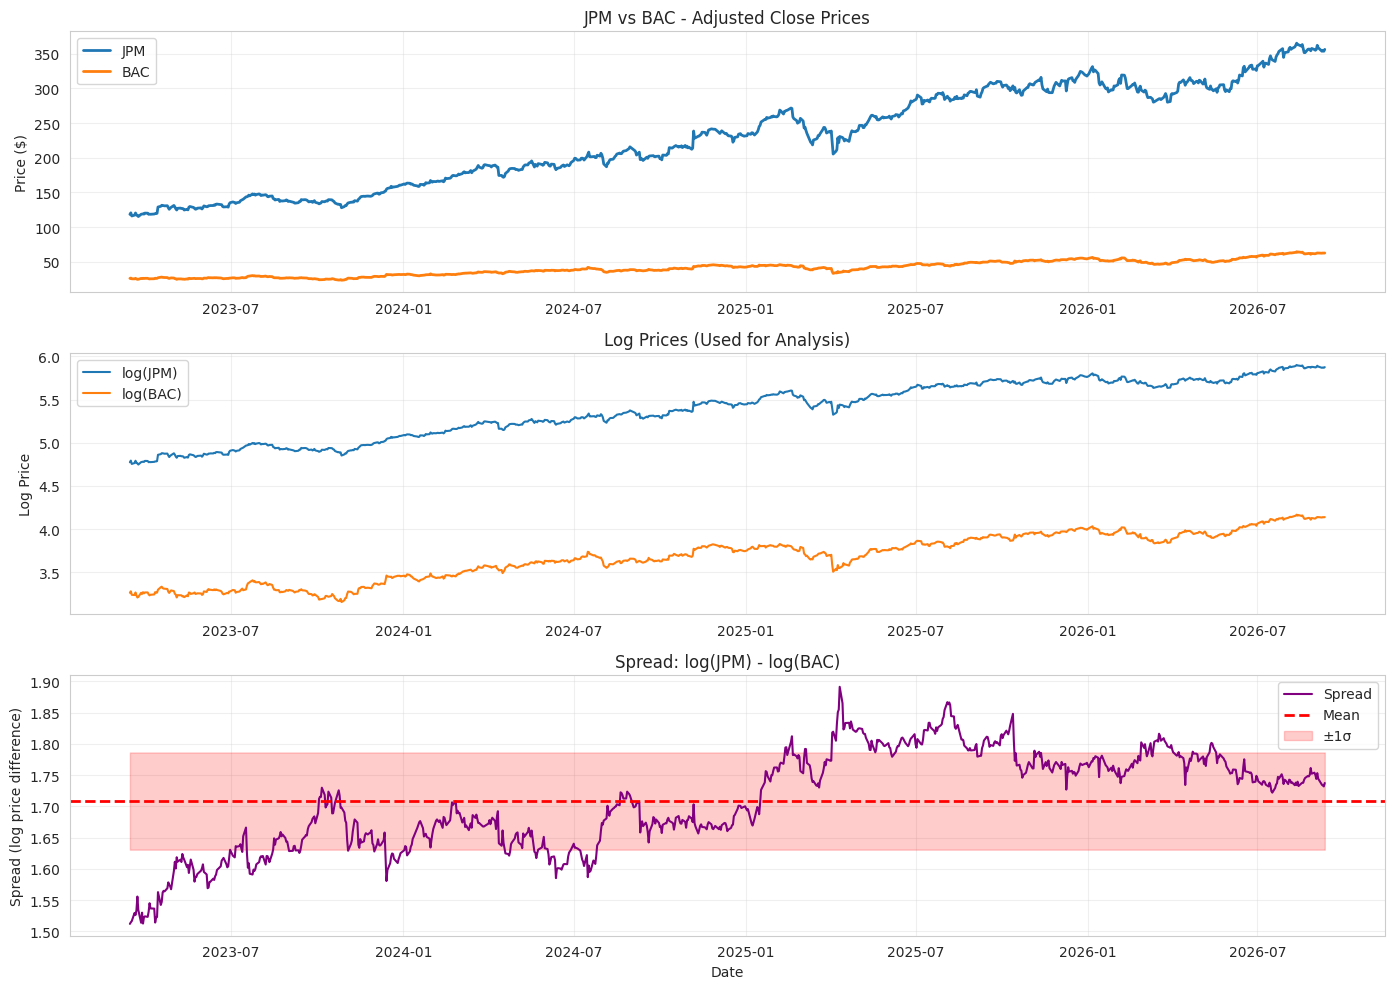


✓ Plot saved as '01_price_exploration_JPM_BAC.png'
Exploring GLD_SLV

Data shape: (877, 2)

First 5 rows:
                   GLD        SLV
Date                             
2023-03-15  178.210007  20.000000
2023-03-16  178.570007  19.920000
2023-03-17  183.770004  20.629999
2023-03-20  183.839996  20.690001
2023-03-21  180.369995  20.540001

Basic statistics:
              GLD         SLV
count  877.000000  877.000000
mean   279.025644   36.062212
std     91.382129   17.750983
min    168.830002   19.250000
25%    188.750000   22.730000
50%    247.029999   28.530001
75%    368.380005   44.340000
max    495.899994  105.599998

Spread Statistics:
  Mean: 2.093396
  Std: 0.146736
  Min: 1.544010
  Max: 2.360271
  Autocorr(1): 0.9924
  Autocorr(5): 0.9633


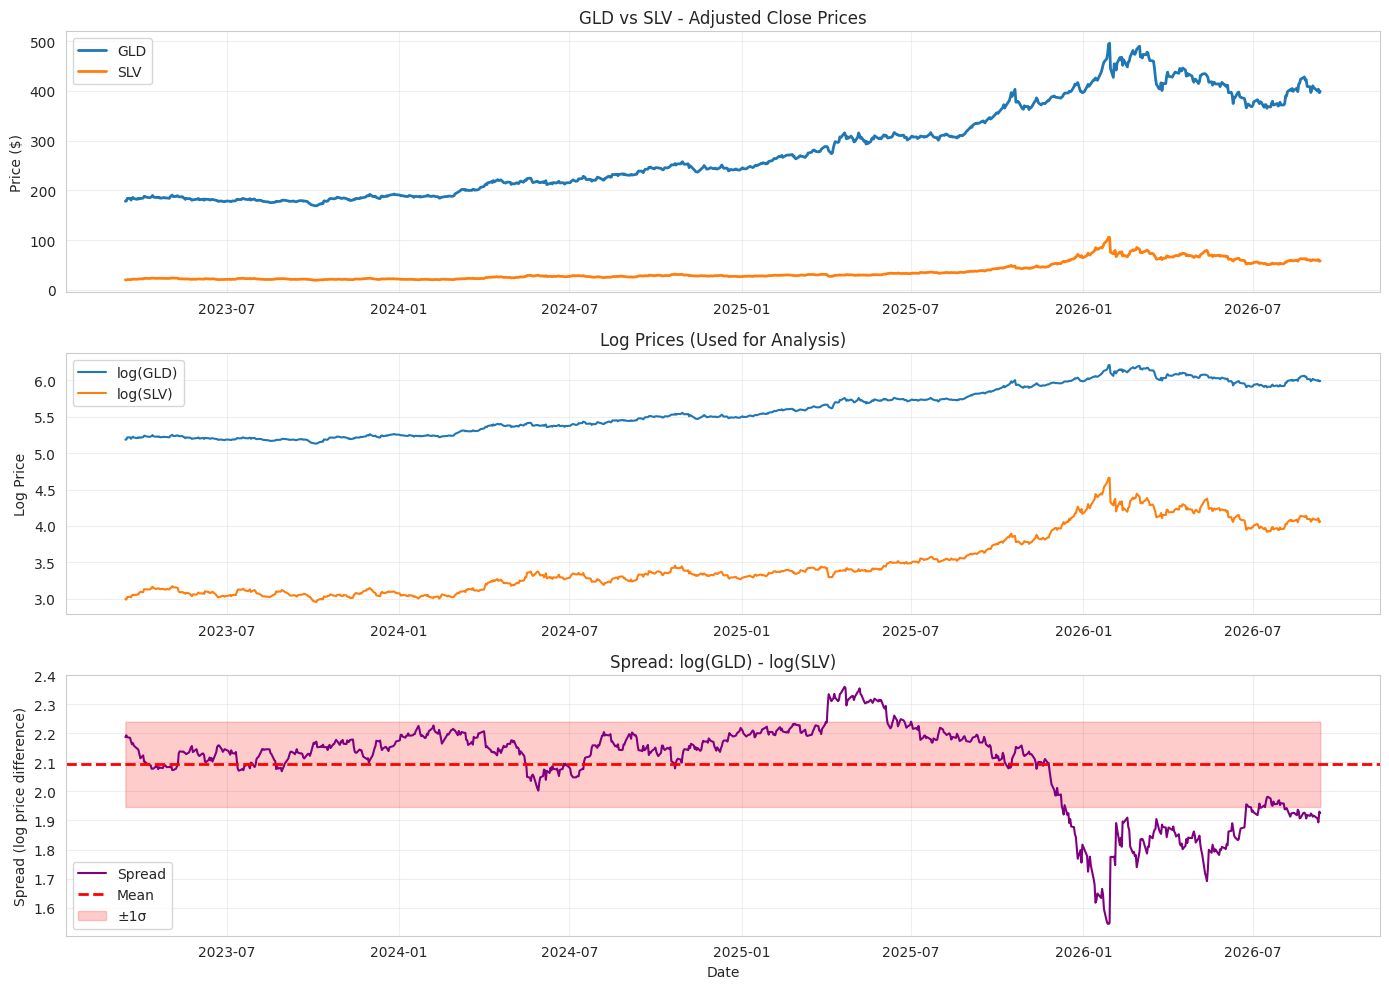


✓ Plot saved as '01_price_exploration_GLD_SLV.png'
Exploring KO_PEP

Data shape: (877, 2)

First 5 rows:
                   KO         PEP
Date                             
2023-03-15  54.487694  156.303192
2023-03-16  54.787529  156.197006
2023-03-17  54.533119  154.975800
2023-03-20  55.060097  157.152710
2023-03-21  54.805698  157.524384

Basic statistics:
               KO         PEP
count  877.000000  877.000000
mean    64.804142  148.721834
std      9.400215   11.560106
min     48.334461  120.925171
25%     56.550575  139.895523
50%     64.890770  150.087524
75%     69.300667  158.039154
max     91.989998  173.550262

Spread Statistics:
  Mean: -0.837707
  Std: 0.188417
  Min: -1.106771
  Max: -0.429233
  Autocorr(1): 0.9986
  Autocorr(5): 0.9929


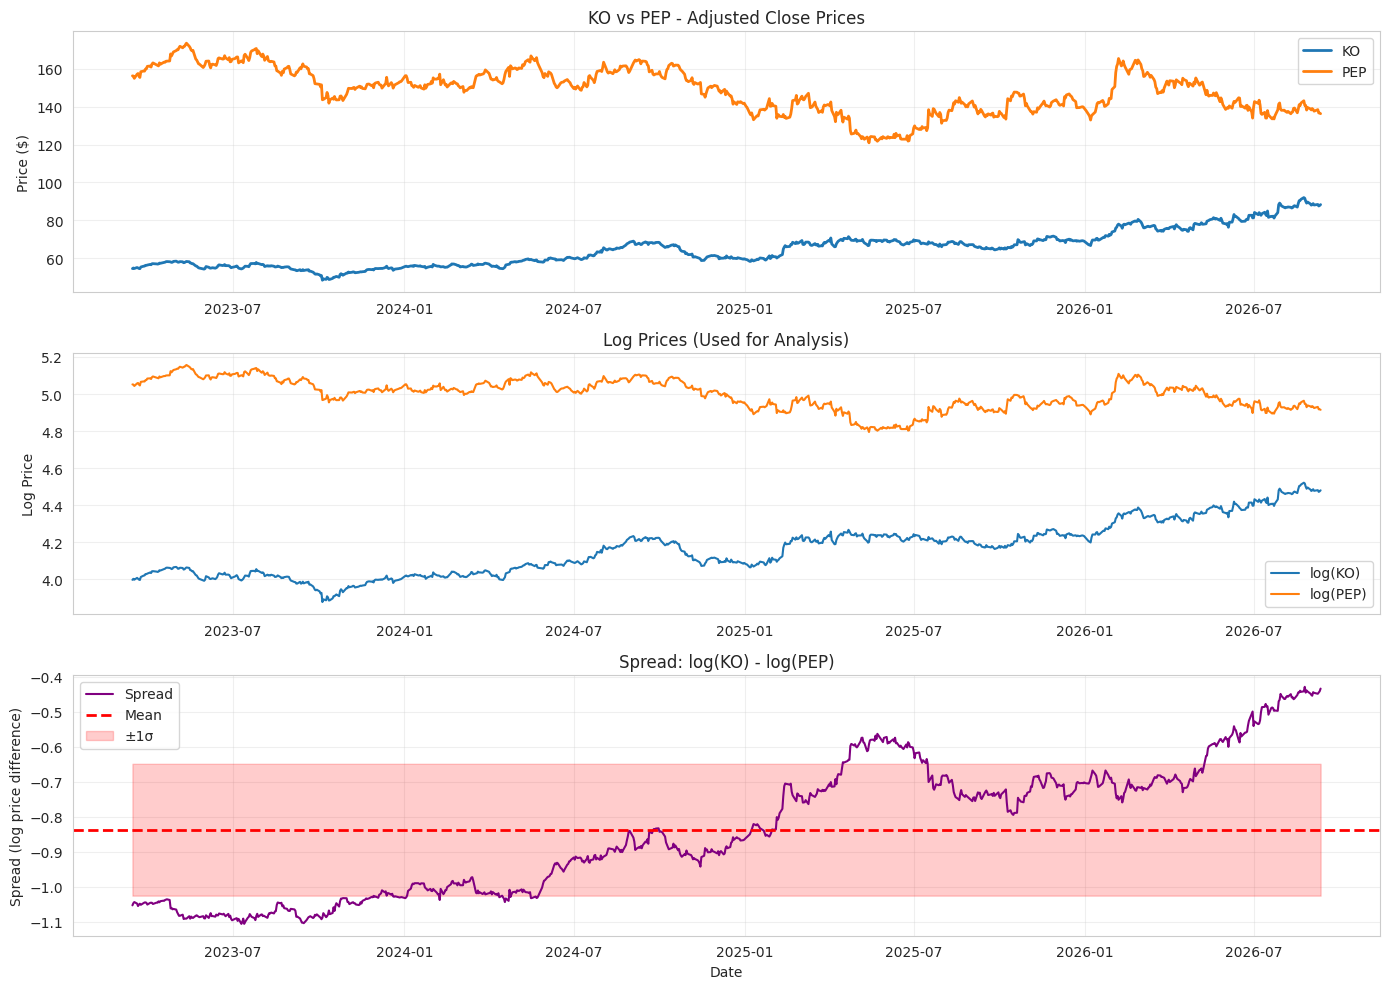


✓ Plot saved as '01_price_exploration_KO_PEP.png'
Exploring GS_MS

Data shape: (877, 2)

First 5 rows:
                    GS         MS
Date                             
2023-03-15  287.399902  76.516891
2023-03-16  290.069641  77.968559
2023-03-17  279.436737  75.432625
2023-03-20  284.951141  76.740906
2023-03-21  292.085754  79.536705

Basic statistics:
                GS          MS
count   877.000000  877.000000
mean    580.606589  122.865051
std     242.644898   44.789436
min     271.163666   64.219429
25%     362.533813   81.696999
50%     530.363647  113.273247
75%     774.918640  156.661087
max    1146.455078  227.298782

Spread Statistics:
  Mean: 1.528819
  Std: 0.087068
  Min: 1.300829
  Max: 1.679434
  Autocorr(1): 0.9937
  Autocorr(5): 0.9746


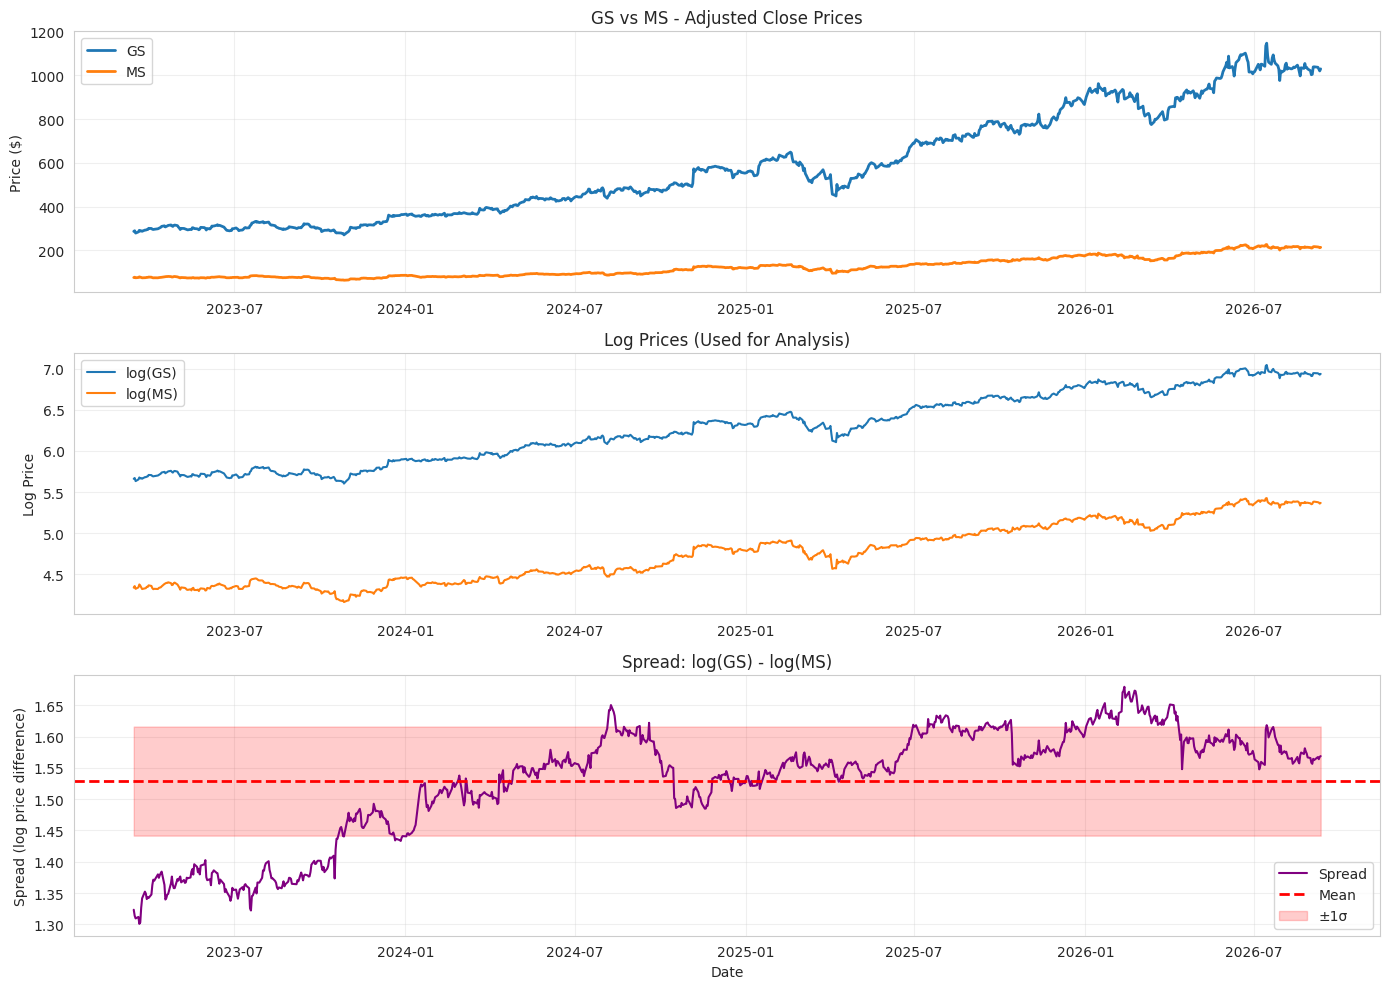


✓ Plot saved as '01_price_exploration_GS_MS.png'
Exploring XOM_CVX

Data shape: (877, 2)

First 5 rows:
                  XOM         CVX
Date                             
2023-03-15  90.548462  133.070709
2023-03-16  90.022743  133.494644
2023-03-17  88.962402  131.807480
2023-03-20  91.288017  133.745605
2023-03-21  95.377953  137.838058

Basic statistics:
              XOM         CVX
count  877.000000  877.000000
mean   112.603112  149.337595
std     19.484623   19.622713
min     88.517349  125.203651
25%    100.027565  136.505630
50%    106.782310  144.285004
75%    113.768517  150.272995
max    169.218277  214.059998

Spread Statistics:
  Mean: -0.287851
  Std: 0.059103
  Min: -0.402319
  Max: -0.167889
  Autocorr(1): 0.9892
  Autocorr(5): 0.9438


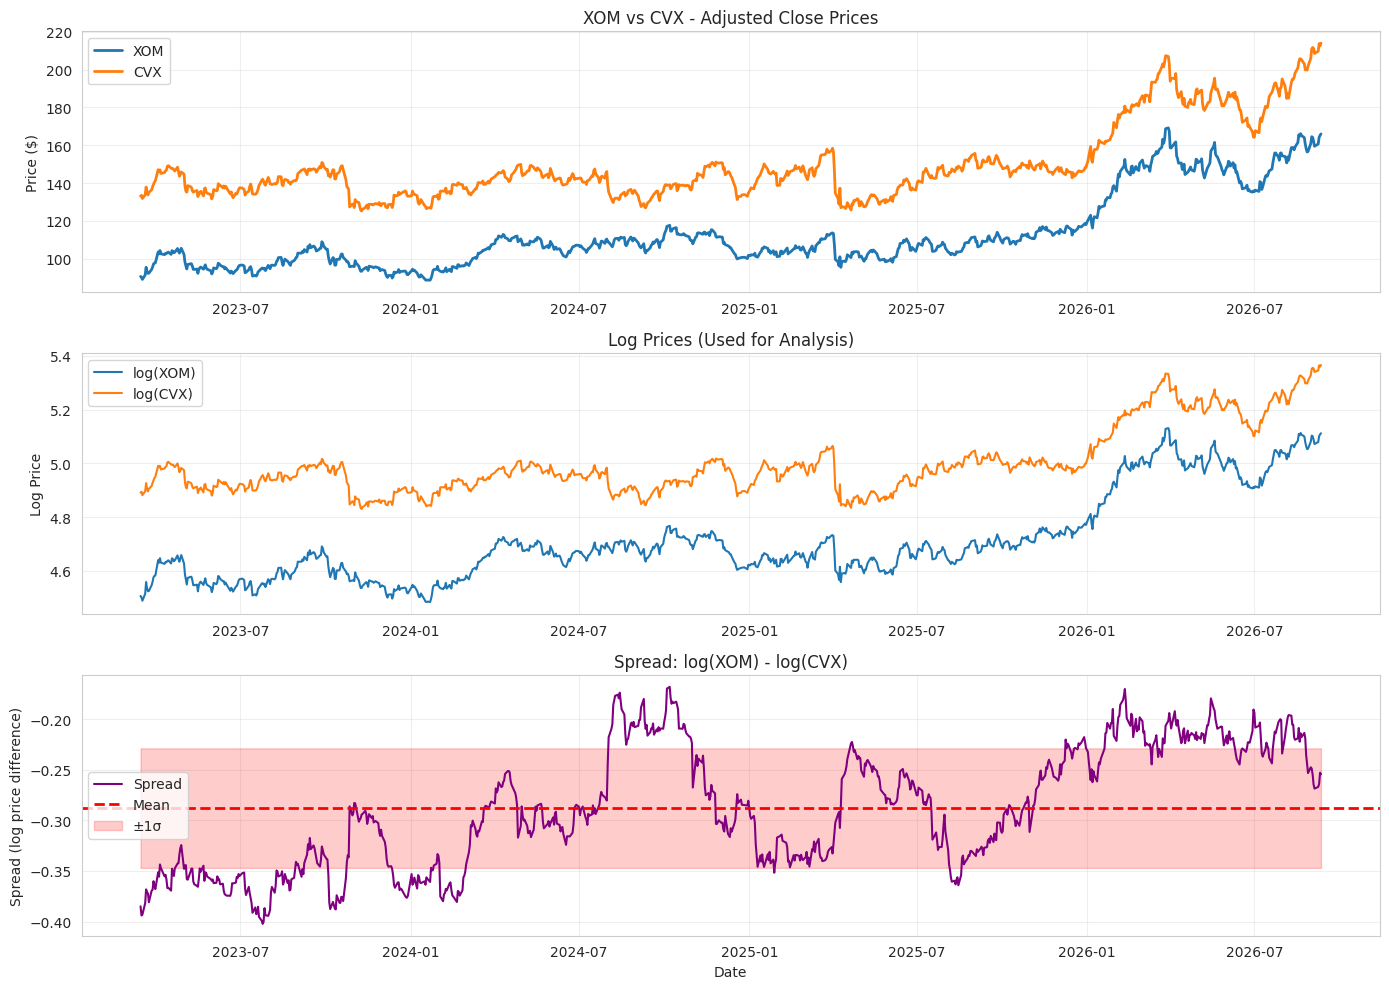


✓ Plot saved as '01_price_exploration_XOM_CVX.png'
Exploring JNJ_PFE

Data shape: (877, 2)

First 5 rows:
                   JNJ        PFE
Date                             
2023-03-15  139.661179  32.495575
2023-03-16  139.371628  32.568180
2023-03-17  137.878677  32.350353
2023-03-20  139.244965  32.923141
2023-03-21  139.244965  32.802135

Basic statistics:
              JNJ         PFE
count  877.000000  877.000000
mean   170.010596   25.152710
std     38.181809    2.857014
min    133.701645   19.461582
25%    144.984222   23.286840
50%    150.582657   24.476641
75%    186.516724   26.153221
max    278.429993   33.713753

Spread Statistics:
  Mean: 1.895071
  Std: 0.222852
  Min: 1.439519
  Max: 2.419604
  Autocorr(1): 0.9978
  Autocorr(5): 0.9891


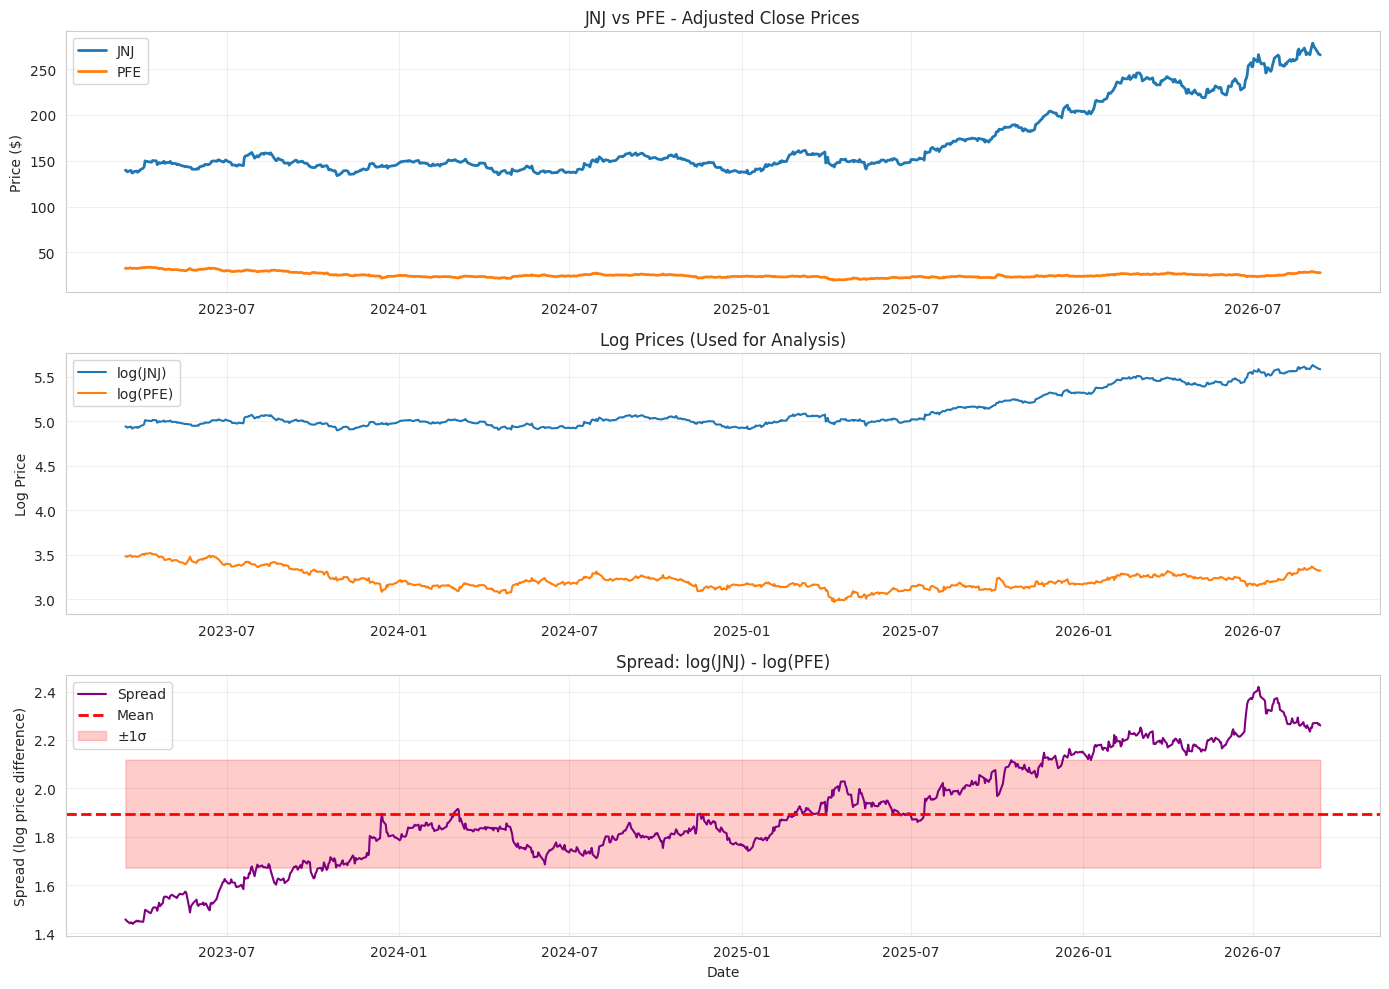


✓ Plot saved as '01_price_exploration_JNJ_PFE.png'
Exploring BA_RTX

Data shape: (877, 2)

First 5 rows:
                    BA        RTX
Date                             
2023-03-15  198.210007  89.092880
2023-03-16  203.190002  91.184700
2023-03-17  201.050003  89.018509
2023-03-20  204.770004  90.673378
2023-03-21  204.699997  91.119606

Basic statistics:
               BA         RTX
count  877.000000  877.000000
mean   200.781870  128.562058
std     26.296002   42.815160
min    136.589996   65.351761
25%    180.229996   91.146568
50%    204.770004  117.578308
75%    219.729996  169.263885
max    264.269989  225.490005

Spread Statistics:
  Mean: 0.491381
  Std: 0.326112
  Min: -0.028878
  Max: 1.243921
  Autocorr(1): 0.9978
  Autocorr(5): 0.9874


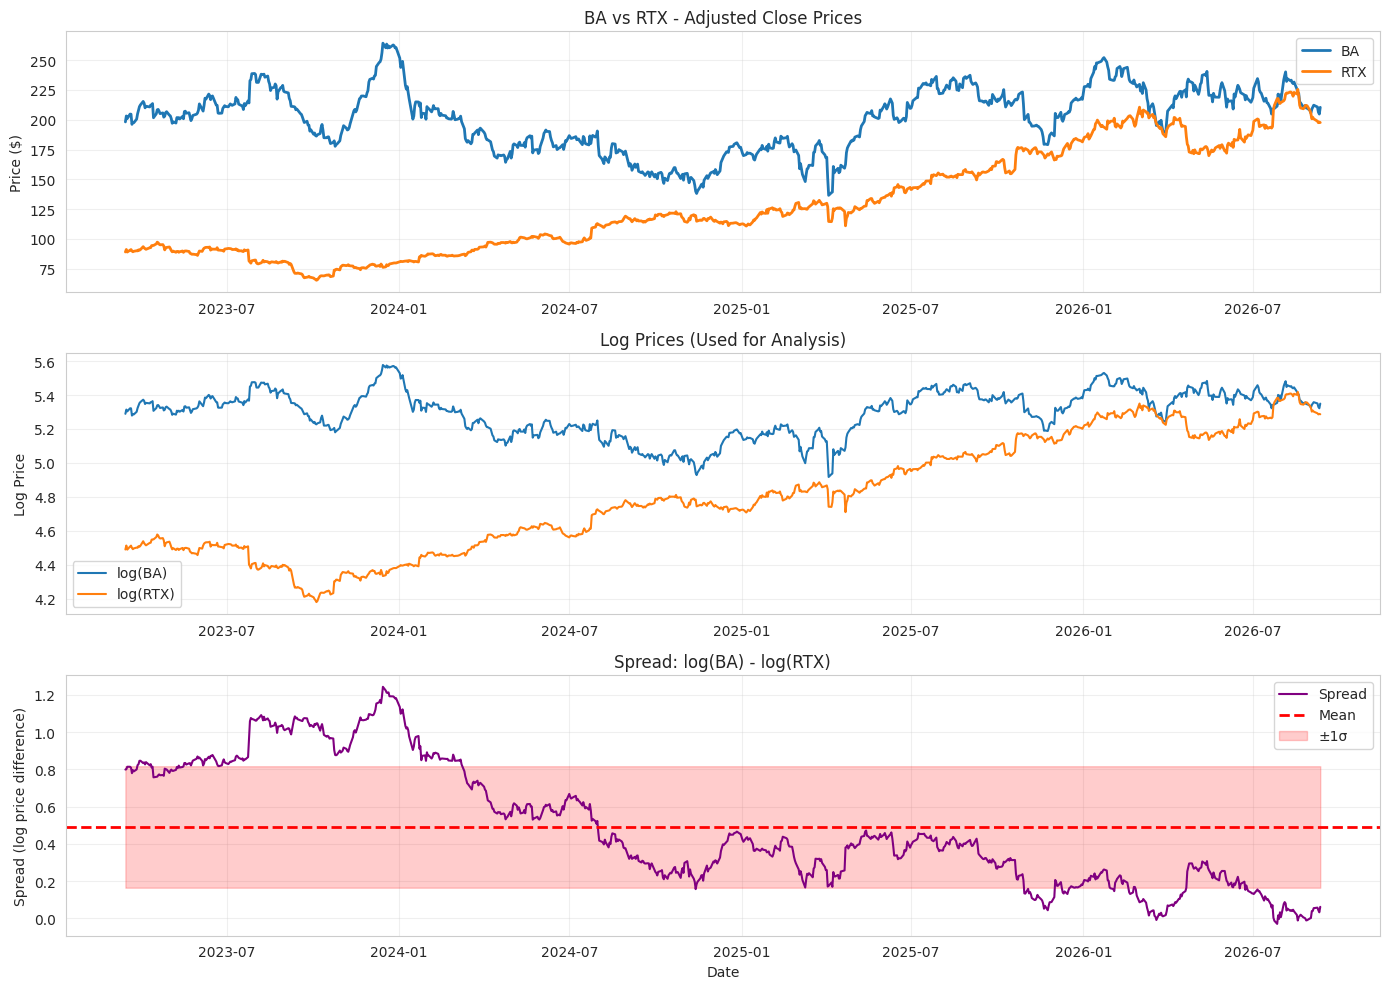


✓ Plot saved as '01_price_exploration_BA_RTX.png'
Exploring MCD_CMG

Data shape: (877, 2)

First 5 rows:
                   MCD        CMG
Date                             
2023-03-15  245.115524  31.817400
2023-03-16  249.008423  32.502800
2023-03-17  245.906998  32.176800
2023-03-20  249.164871  32.204601
2023-03-21  248.677109  32.559200

Basic statistics:
              MCD         CMG
count  877.000000  877.000000
mean   278.080247   45.692227
std     20.800074   10.090616
min    228.998535   28.180000
25%    263.729919   37.139999
50%    276.417236   42.880001
75%    295.509552   54.320000
max    334.502960   68.552200

Spread Statistics:
  Mean: 1.827519
  Std: 0.244797
  Min: 1.242751
  Max: 2.306054
  Autocorr(1): 0.9959
  Autocorr(5): 0.9797


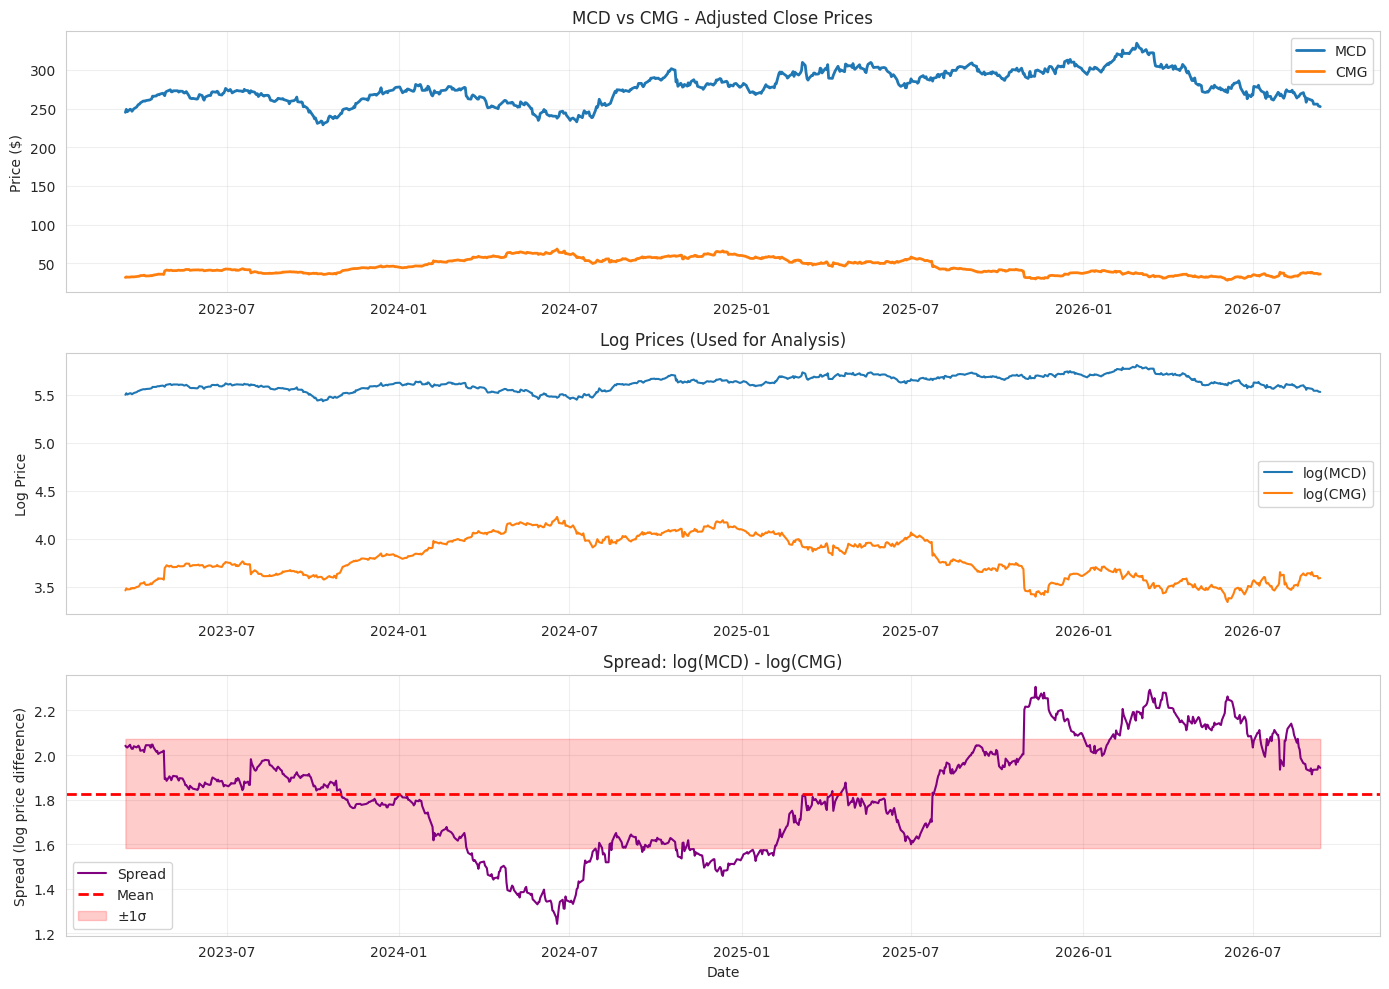


✓ Plot saved as '01_price_exploration_MCD_CMG.png'
Exploring XLU_XLE

Data shape: (877, 2)

First 5 rows:
                  XLU        XLE
Date                            
2023-03-15  30.220446  34.469624
2023-03-16  30.422907  34.843906
2023-03-17  30.130466  34.295860
2023-03-20  30.366138  34.982449
2023-03-21  29.754284  36.193546

Basic statistics:
              XLU         XLE
count  877.000000  877.000000
mean    36.701047   44.137106
std      6.049018    6.840022
min     25.879629   34.295860
25%     30.384602   39.728813
50%     37.433941   42.394024
75%     42.282505   44.613899
max     47.097874   65.309998

Spread Statistics:
  Mean: -0.187599
  Std: 0.117926
  Min: -0.448676
  Max: 0.076043
  Autocorr(1): 0.9921
  Autocorr(5): 0.9588


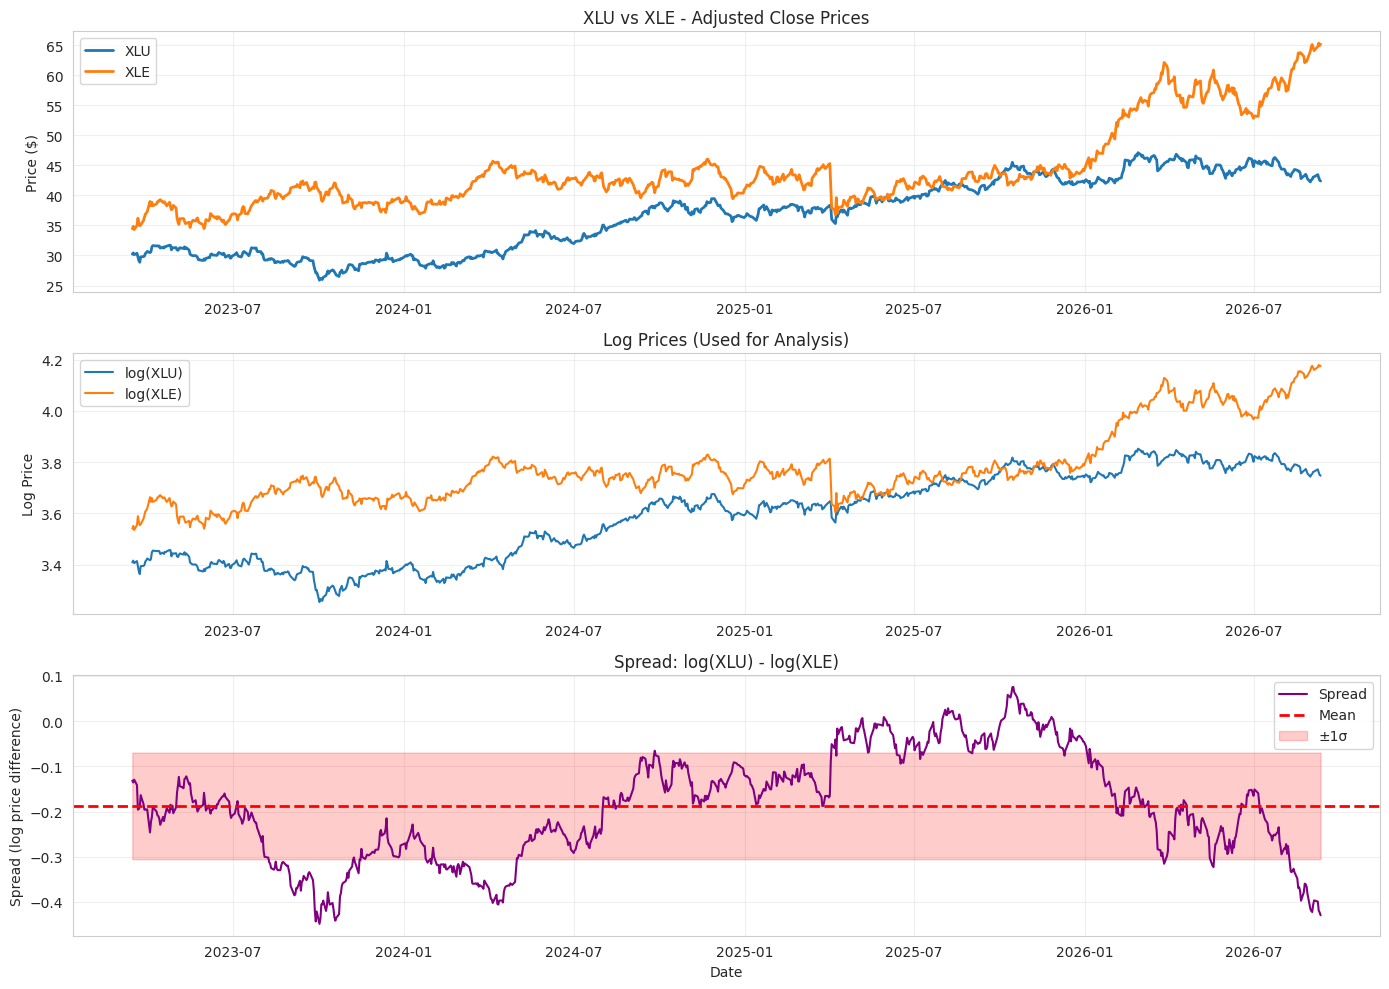


✓ Plot saved as '01_price_exploration_XLU_XLE.png'
Exploring XLV_XLY

Data shape: (877, 2)

First 5 rows:
                   XLV        XLY
Date                             
2023-03-15  119.171341  68.270172
2023-03-16  120.284576  69.503227
2023-03-17  118.737373  68.614845
2023-03-20  120.242294  68.911888
2023-03-21  120.971565  70.815811

Basic statistics:
              XLV         XLY
count  877.000000  877.000000
mean   139.490868   99.246511
std     11.756601   15.735763
min    117.584839   68.270172
25%    129.821960   85.637062
50%    139.777359   98.567955
75%    146.660568  114.631577
max    175.679993  124.023224

Spread Statistics:
  Mean: 0.349971
  Std: 0.119939
  Min: 0.113360
  Max: 0.595878
  Autocorr(1): 0.9945
  Autocorr(5): 0.9716


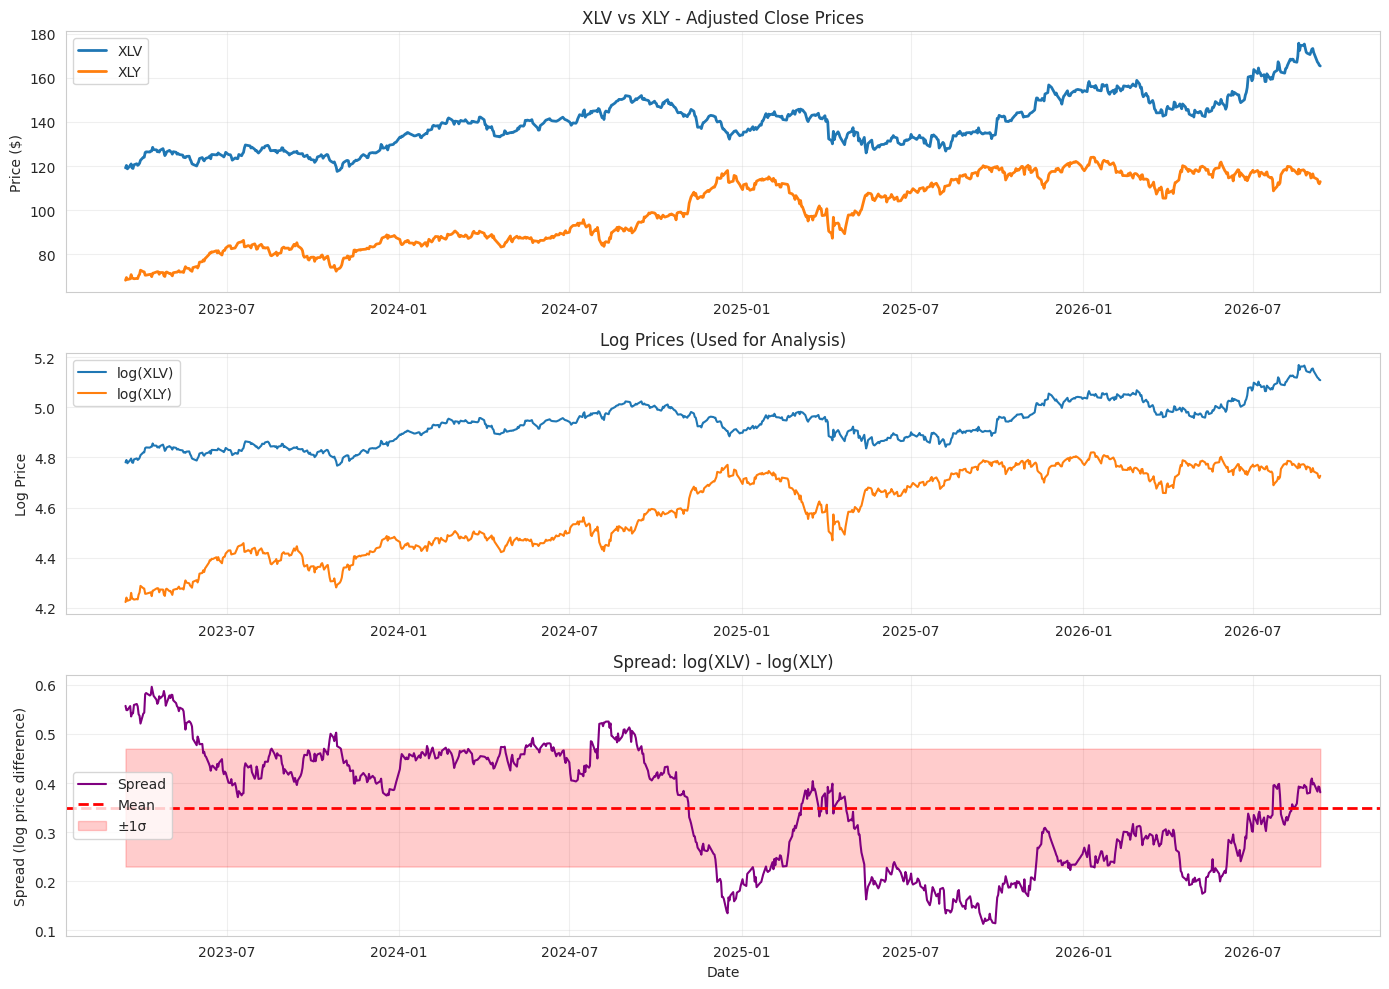


✓ Plot saved as '01_price_exploration_XLV_XLY.png'
Exploring IVV_VOO

Data shape: (877, 2)

First 5 rows:
                   IVV         VOO
Date                              
2023-03-15  372.991547  341.210449
2023-03-16  379.408905  347.047668
2023-03-17  374.908051  343.251587
2023-03-20  378.627014  346.351349
2023-03-21  383.547302  350.881958

Basic statistics:
              IVV         VOO
count  877.000000  877.000000
mean   566.700267  518.492303
std    110.362276  100.975434
min    372.991547  341.210449
25%    475.043579  434.658081
50%    563.627197  515.653503
75%    660.977295  604.704651
max    781.469971  714.950012

Spread Statistics:
  Mean: 0.088907
  Std: 0.000261
  Min: 0.085612
  Max: 0.090256
  Autocorr(1): 0.0718
  Autocorr(5): -0.0145


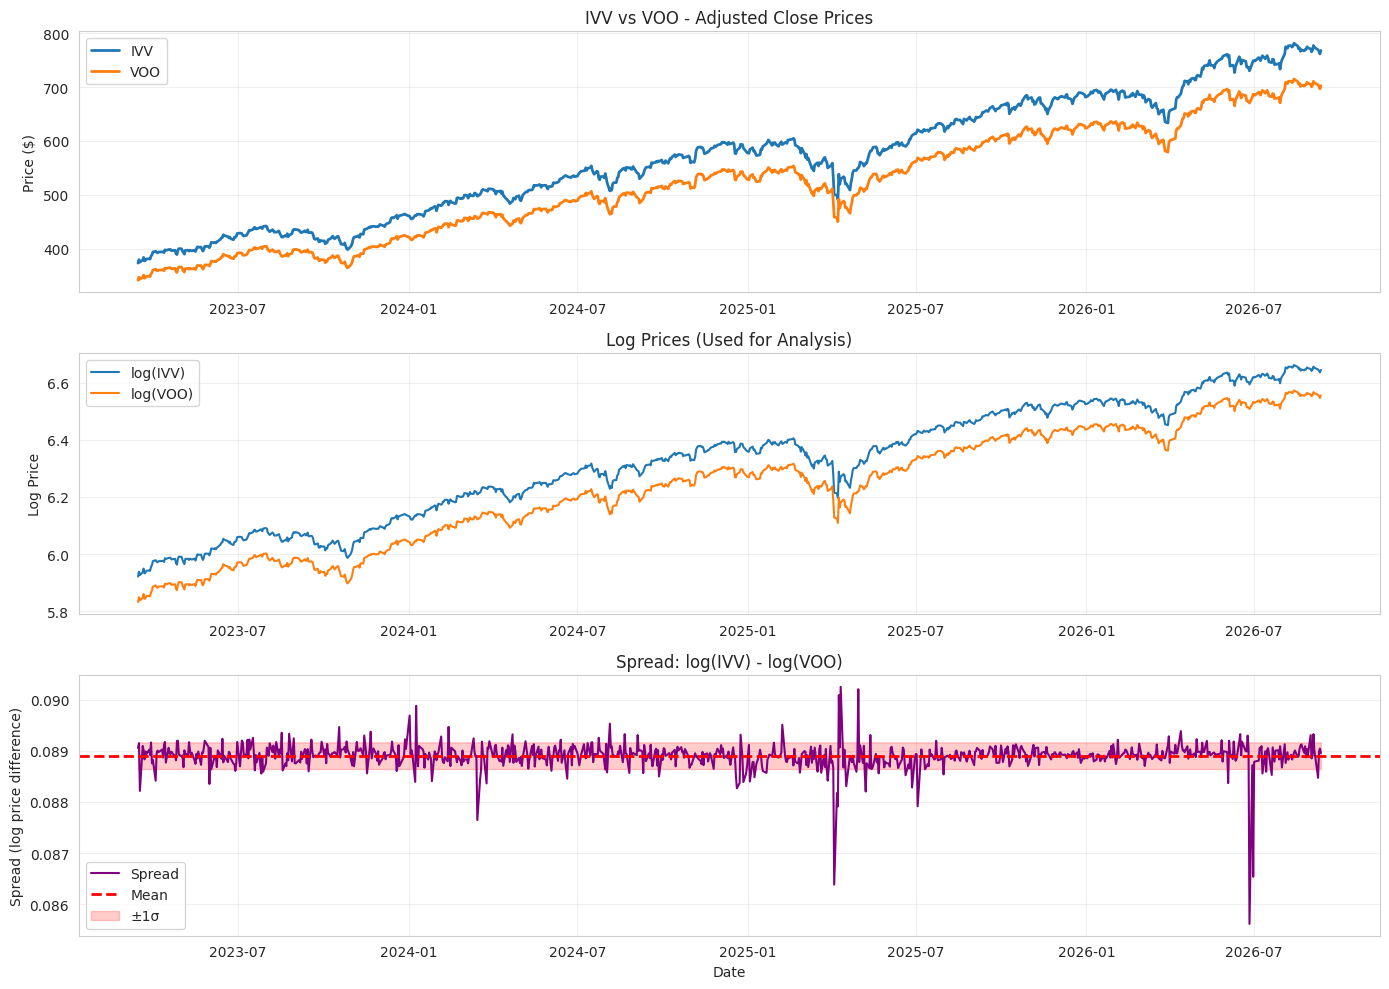


✓ Plot saved as '01_price_exploration_IVV_VOO.png'
Exploring EEM_VWO

Data shape: (877, 2)

First 5 rows:
                  EEM        VWO
Date                            
2023-03-15  34.432228  34.899467
2023-03-16  34.958836  35.344219
2023-03-17  34.746346  35.162685
2023-03-20  34.875687  35.224442
2023-03-21  35.189800  35.596859

Basic statistics:
              EEM         VWO
count  877.000000  877.000000
mean    45.902195   45.561629
std      9.982167    7.947205
min     34.012970   34.747486
25%     37.843864   38.292896
50%     41.859325   43.343735
75%     53.139381   53.003788
max     71.209999   61.439999

Spread Statistics:
  Mean: 0.000531
  Std: 0.044101
  Min: -0.052032
  Max: 0.152622
  Autocorr(1): 0.9965
  Autocorr(5): 0.9871


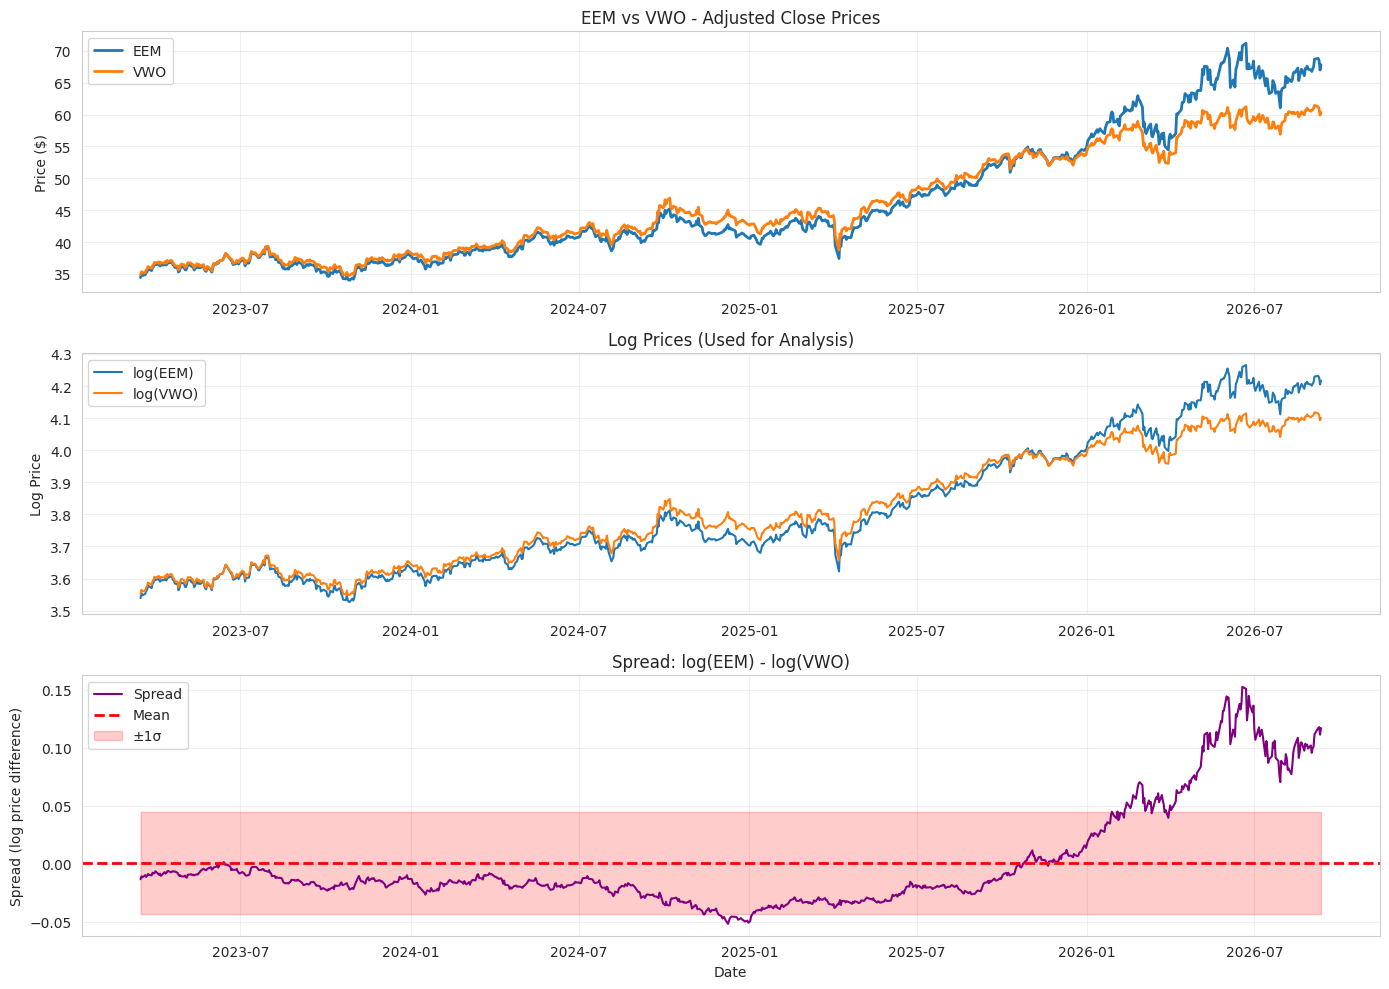


✓ Plot saved as '01_price_exploration_EEM_VWO.png'


In [67]:
for stock1, stock2 in pairs:

    pair_name = f'{stock1}_{stock2}'
    data = all_data[pair_name]

    print(f"Exploring {pair_name}")
    print("="*70)
    print(f"\nData shape: {data.shape}")
    print(f"\nFirst 5 rows:\n{data.head()}")
    print(f"\nBasic statistics:\n{data.describe()}")

    # Calculate log prices (better for returns)
    log_prices = np.log(data)

    # Calculate spread
    spread = log_prices[stock1] - log_prices[stock2]

    print(f"\nSpread Statistics:")
    print(f"  Mean: {spread.mean():.6f}")
    print(f"  Std: {spread.std():.6f}")
    print(f"  Min: {spread.min():.6f}")
    print(f"  Max: {spread.max():.6f}")
    print(f"  Autocorr(1): {spread.autocorr(1):.4f}")
    print(f"  Autocorr(5): {spread.autocorr(5):.4f}")

    # Plot
    fig, axes = plt.subplots(3, 1, figsize=(14, 10))

    # Plot 1: Stock prices
    axes[0].plot(data.index, data[stock1], label=stock1, linewidth=2)
    axes[0].plot(data.index, data[stock2], label=stock2, linewidth=2)
    axes[0].set_ylabel('Price ($)')
    axes[0].set_title(f'{stock1} vs {stock2} - Adjusted Close Prices')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Plot 2: Log prices
    axes[1].plot(log_prices.index, log_prices[stock1], label=f'log({stock1})', linewidth=1.5)
    axes[1].plot(log_prices.index, log_prices[stock2], label=f'log({stock2})', linewidth=1.5)
    axes[1].set_ylabel('Log Price')
    axes[1].set_title('Log Prices (Used for Analysis)')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    # Plot 3: Spread
    axes[2].plot(spread.index, spread.values, label='Spread', linewidth=1.5, color='purple')
    axes[2].axhline(spread.mean(), color='red', linestyle='--', label='Mean', linewidth=2)
    axes[2].fill_between(
        spread.index,
        spread.mean() - spread.std(),
        spread.mean() + spread.std(),
        alpha=0.2,
        color='red',
        label='±1σ'
    )
    axes[2].set_ylabel('Spread (log price difference)')
    axes[2].set_xlabel('Date')
    axes[2].set_title(f'Spread: log({stock1}) - log({stock2})')
    axes[2].legend()
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(f'01_price_exploration_{pair_name}.png', dpi=150, bbox_inches='tight')
    plt.show()

    print(f"\n✓ Plot saved as '01_price_exploration_{pair_name}.png'")

In [53]:
# Function to run ADF test
def adf_test(series, name):
    """Run Augmented Dickey-Fuller test"""
    result = adfuller(series.dropna(), autolag='AIC')

    print(f"\n{name}")
    print("-" * 50)
    print(f"ADF Statistic: {result[0]:.6f}")
    print(f"P-value: {result[1]:.6f}")
    print(f"Critical Values:")
    for key, val in result[4].items():
        print(f"  {key}: {val:.3f}")

    if result[1] < 0.05:
        print(f"✓ Result: {name} is STATIONARY (p < 0.05)")
        return True
    else:
        print(f"✗ Result: {name} is NON-STATIONARY (p >= 0.05)")
        return False

# Test all three pairs
print("\n" + "="*70)
print("STATIONARITY TESTS (ADF)")
print("="*70)

adf_results = {}

for pair_key, data in all_data.items():
    stock1, stock2 = pair_key.split('_')
    log_prices = np.log(data)
    spread = log_prices[stock1] - log_prices[stock2]

    print(f"\n{'='*70}")
    print(f"Pair: {pair_key}")
    print(f"{'='*70}")

    # Test individual prices
    adf_test(log_prices[stock1], f"  {stock1} (log price)")
    adf_test(log_prices[stock2], f"  {stock2} (log price)")

    # Test spread
    is_stationary = adf_test(spread, f"  Spread ({stock1} - {stock2})")
    adf_results[pair_key] = is_stationary

print("\n" + "="*70)
print("SUMMARY OF STATIONARITY TESTS")
print("="*70)
for pair, is_stat in adf_results.items():
    status = "✓ STATIONARY" if is_stat else "✗ NON-STATIONARY"
    print(f"{pair}: {status}")


STATIONARITY TESTS (ADF)

Pair: AAPL_MSFT

  AAPL (log price)
--------------------------------------------------
ADF Statistic: -0.810242
P-value: 0.816095
Critical Values:
  1%: -3.438
  5%: -2.865
  10%: -2.569
✗ Result:   AAPL (log price) is NON-STATIONARY (p >= 0.05)

  MSFT (log price)
--------------------------------------------------
ADF Statistic: -2.543003
P-value: 0.105359
Critical Values:
  1%: -3.438
  5%: -2.865
  10%: -2.569
✗ Result:   MSFT (log price) is NON-STATIONARY (p >= 0.05)

  Spread (AAPL - MSFT)
--------------------------------------------------
ADF Statistic: -1.735134
P-value: 0.413107
Critical Values:
  1%: -3.438
  5%: -2.865
  10%: -2.569
✗ Result:   Spread (AAPL - MSFT) is NON-STATIONARY (p >= 0.05)

Pair: JPM_BAC

  JPM (log price)
--------------------------------------------------
ADF Statistic: -1.109409
P-value: 0.711305
Critical Values:
  1%: -3.438
  5%: -2.865
  10%: -2.569
✗ Result:   JPM (log price) is NON-STATIONARY (p >= 0.05)

  BAC (log pric

In [54]:
# Function to run Engle-Granger cointegration test
def engle_granger_test(price1, price2, name1, name2):
    """Run Engle-Granger cointegration test"""
    score, pvalue, _ = coint(price1, price2)

    print(f"\n{name1} vs {name2}")
    print("-" * 50)
    print(f"Test Statistic: {score:.6f}")
    print(f"P-value: {pvalue:.6f}")

    if pvalue < 0.05:
        print(f"✓ Result: COINTEGRATED (p < 0.05)")
        print(f"  → Pairs move together and share long-term equilibrium")
        return True
    else:
        print(f"✗ Result: NOT COINTEGRATED (p >= 0.05)")
        print(f"  → Spread is not mean-reverting; risky for trading")
        return False

# Run Engle-Granger test for all pairs
print("\n" + "="*70)
print("COINTEGRATION TESTS (Engle-Granger)")
print("="*70)

cointegration_results = {}

for pair_key, data in all_data.items():
    stock1, stock2 = pair_key.split('_')
    log_prices = np.log(data)

    print(f"\n{'='*70}")
    print(f"Pair: {pair_key}")
    print(f"{'='*70}")

    is_cointegrated = engle_granger_test(
        log_prices[stock1].values,
        log_prices[stock2].values,
        stock1,
        stock2
    )

    cointegration_results[pair_key] = is_cointegrated

print("\n" + "="*70)
print("SUMMARY OF COINTEGRATION TESTS")
print("="*70)
for pair, is_coint in cointegration_results.items():
    status = "✓ COINTEGRATED" if is_coint else "✗ NOT COINTEGRATED"
    print(f"{pair}: {status}")


COINTEGRATION TESTS (Engle-Granger)

Pair: AAPL_MSFT

AAPL vs MSFT
--------------------------------------------------
Test Statistic: -1.340265
P-value: 0.817255
✗ Result: NOT COINTEGRATED (p >= 0.05)
  → Spread is not mean-reverting; risky for trading

Pair: JPM_BAC

JPM vs BAC
--------------------------------------------------
Test Statistic: -3.146087
P-value: 0.079416
✗ Result: NOT COINTEGRATED (p >= 0.05)
  → Spread is not mean-reverting; risky for trading

Pair: GLD_SLV

GLD vs SLV
--------------------------------------------------
Test Statistic: -2.174071
P-value: 0.437772
✗ Result: NOT COINTEGRATED (p >= 0.05)
  → Spread is not mean-reverting; risky for trading

Pair: KO_PEP

KO vs PEP
--------------------------------------------------
Test Statistic: -1.629220
P-value: 0.708400
✗ Result: NOT COINTEGRATED (p >= 0.05)
  → Spread is not mean-reverting; risky for trading

Pair: GS_MS

GS vs MS
--------------------------------------------------
Test Statistic: -3.005510
P-value: 

In [55]:
# Select pairs that are both stationary and cointegrated
print("\n" + "="*70)
print("PAIR SELECTION FOR TRADING")
print("="*70)

valid_pairs = {}
for pair_key in all_data.keys():
    is_stat = adf_results[pair_key]
    is_coint = cointegration_results[pair_key]

    if is_stat and is_coint:
        valid_pairs[pair_key] = all_data[pair_key]
        print(f"\n✓ {pair_key}: VALID for trading")
        print(f"  - Spread is stationary ✓")
        print(f"  - Pairs are cointegrated ✓")
    else:
        print(f"\n✗ {pair_key}: NOT SUITABLE")
        if not is_stat:
            print(f"  - Spread not stationary ✗")
        if not is_coint:
            print(f"  - Not cointegrated ✗")

# Choose the first valid pair for analysis
if len(valid_pairs) > 0:
    selected_pair = list(valid_pairs.keys())[0]
    selected_data = valid_pairs[selected_pair]
    stock1, stock2 = selected_pair.split('_')

    print(f"\n{'='*70}")
    print(f"SELECTED PAIR FOR MCMC ANALYSIS: {selected_pair}")
    print(f"{'='*70}")
else:
    print("\nNo valid pairs found!")
    selected_pair = list(all_data.keys())[1]
    selected_data = all_data[selected_pair]
    stock1, stock2 = selected_pair.split('_')
    print(f"Using second pair because of the best co-integration: {selected_pair}")

print(f"\nData shape: {selected_data.shape}")
print(f"Date range: {selected_data.index[0].date()} to {selected_data.index[-1].date()}")


PAIR SELECTION FOR TRADING

✗ AAPL_MSFT: NOT SUITABLE
  - Spread not stationary ✗
  - Not cointegrated ✗

✗ JPM_BAC: NOT SUITABLE
  - Spread not stationary ✗
  - Not cointegrated ✗

✗ GLD_SLV: NOT SUITABLE
  - Spread not stationary ✗
  - Not cointegrated ✗

✗ KO_PEP: NOT SUITABLE
  - Spread not stationary ✗
  - Not cointegrated ✗

✗ GS_MS: NOT SUITABLE
  - Spread not stationary ✗
  - Not cointegrated ✗

✗ XOM_CVX: NOT SUITABLE
  - Spread not stationary ✗
  - Not cointegrated ✗

✗ JNJ_PFE: NOT SUITABLE
  - Spread not stationary ✗
  - Not cointegrated ✗

✗ BA_RTX: NOT SUITABLE
  - Spread not stationary ✗
  - Not cointegrated ✗

✗ MCD_CMG: NOT SUITABLE
  - Spread not stationary ✗
  - Not cointegrated ✗

✗ XLU_XLE: NOT SUITABLE
  - Spread not stationary ✗
  - Not cointegrated ✗

✗ XLV_XLY: NOT SUITABLE
  - Spread not stationary ✗
  - Not cointegrated ✗

✓ IVV_VOO: VALID for trading
  - Spread is stationary ✓
  - Pairs are cointegrated ✓

✗ EEM_VWO: NOT SUITABLE
  - Spread not stationary ✗


DATA PREPARATION FOR MCMC

Spread statistics:
  Mean: 0.088907
  Std: 0.000261
  Length: 877 observations

Daily changes (for OU model):
  Mean change: -0.000000
  Std of changes: 0.000356
  Number of changes: 876


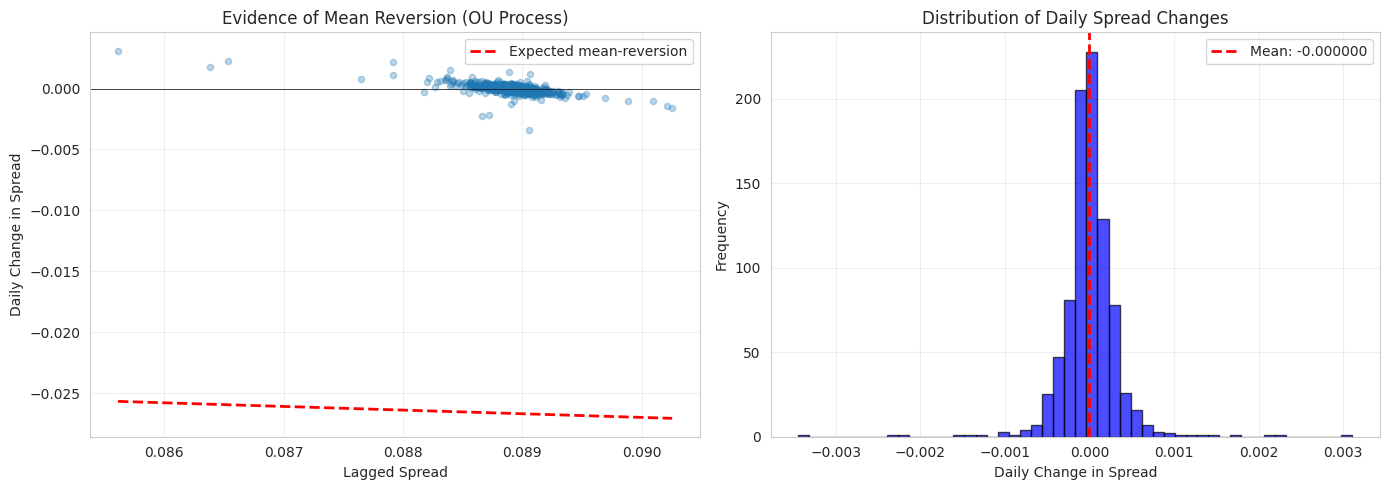


✓ Data prepared and visualized


In [56]:
# Prepare data for MCMC inference
print("\n" + "="*70)
print("DATA PREPARATION FOR MCMC")
print("="*70)

# Calculate log prices and spread
log_prices = np.log(selected_data)
spread = log_prices[stock1] - log_prices[stock2]

print(f"\nSpread statistics:")
print(f"  Mean: {spread.mean():.6f}")
print(f"  Std: {spread.std():.6f}")
print(f"  Length: {len(spread)} observations")

# Calculate daily changes (first differences)
spread_values = spread.values
changes = np.diff(spread_values)
lagged_spread = spread_values[:-1]

print(f"\nDaily changes (for OU model):")
print(f"  Mean change: {changes.mean():.6f}")
print(f"  Std of changes: {changes.std():.6f}")
print(f"  Number of changes: {len(changes)}")

# Plot changes vs lagged spread (should show mean-reversion)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter: Lagged spread vs changes
axes[0].scatter(lagged_spread, changes, alpha=0.3, s=20)
x_range = np.linspace(lagged_spread.min(), lagged_spread.max(), 100)
y_pred_naive = -0.3 * (lagged_spread)  # Rough expectation of mean-reversion
axes[0].plot(x_range, -0.3 * x_range, 'r--', linewidth=2, label='Expected mean-reversion')
axes[0].axhline(0, color='black', linestyle='-', linewidth=0.5)
axes[0].set_xlabel('Lagged Spread')
axes[0].set_ylabel('Daily Change in Spread')
axes[0].set_title('Evidence of Mean Reversion (OU Process)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Distribution of changes
axes[1].hist(changes, bins=50, alpha=0.7, color='blue', edgecolor='black')
axes[1].axvline(changes.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {changes.mean():.6f}')
axes[1].set_xlabel('Daily Change in Spread')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Distribution of Daily Spread Changes')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('02_mcmc_data_prep.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✓ Data prepared and visualized")

In [57]:
# PyMC Bayesian Model for Ornstein-Uhlenbeck Process
# Model: change_t = β * (μ - lagged_spread_t) + ε_t
#        where ε_t ~ N(0, σ²)

print("\n" + "="*70)
print("MCMC INFERENCE USING PYMC (Ornstein-Uhlenbeck)")
print("="*70)

# Build model using PyMC
with pm.Model() as model_ou:

    # Priors
    # β (mean-reversion speed): Beta(2, 5) → typically 0.1-0.5
    beta = pm.Beta('beta', alpha=2, beta=5)

    # μ (long-term mean): Normal(0, 1)
    mu = pm.Normal('mu', mu=0, sigma=1)

    # σ (volatility): HalfNormal(0.1)
    sigma = pm.HalfNormal('sigma', sigma=0.1)

    # Deterministic: Half-life (days until 50% reversion)
    half_life = pm.Deterministic('half_life', np.log(2) / (beta + 1e-6))

    # Expected change: β * (μ - S_t)
    mu_predicted = beta * (mu - lagged_spread)

    # Likelihood: observed changes
    obs = pm.Normal('obs', mu=mu_predicted, sigma=sigma, observed=changes)

    # Sample from posterior using NUTS sampler (better than Metropolis-Hastings)
    print("\nSampling from posterior using NUTS sampler...")
    trace = pm.sample(
        draws=2000,           # Number of draws after tuning
        tune=1000,            # Tuning (burnin) iterations
        cores=4,              # Use all CPU cores
        chains=4,             # Run 4 independent chains
        random_seed=42,
        return_inferencedata=True,
        progressbar=True,
        target_accept=0.95    # Higher acceptance rate for better mixing
    )

print("\n✓ MCMC sampling complete")


MCMC INFERENCE USING PYMC (Ornstein-Uhlenbeck)

Sampling from posterior using NUTS sampler...


Output()


✓ MCMC sampling complete



CONVERGENCE DIAGNOSTICS

1. Potential Scale Reduction Factor (R̂):
   R̂ < 1.01 → Good convergence
   R̂ > 1.05 → Poor convergence (need more samples)
--------------------------------------------------
<xarray.Dataset> Size: 32B
Dimensions:    ()
Data variables:
    beta       float64 8B 1.0
    half_life  float64 8B 1.0
    mu         float64 8B 1.002
    sigma      float64 8B 1.001
Attributes:
    created_at:                 2026-09-12T07:02:33.607491+00:00
    arviz_version:              0.22.0
    inference_library:          pymc
    inference_library_version:  5.28.5
    sampling_time:              31.622950553894043
    tuning_steps:               1000

2. POSTERIOR SUMMARY STATISTICS
            mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  \
beta       0.886  0.029   0.831    0.938        0.0      0.0    6149.0   
mu         0.089  0.000   0.089    0.089        0.0      0.0    7825.0   
sigma      0.000  0.000   0.000    0.000        0.0      0.0    7568.0   
hal

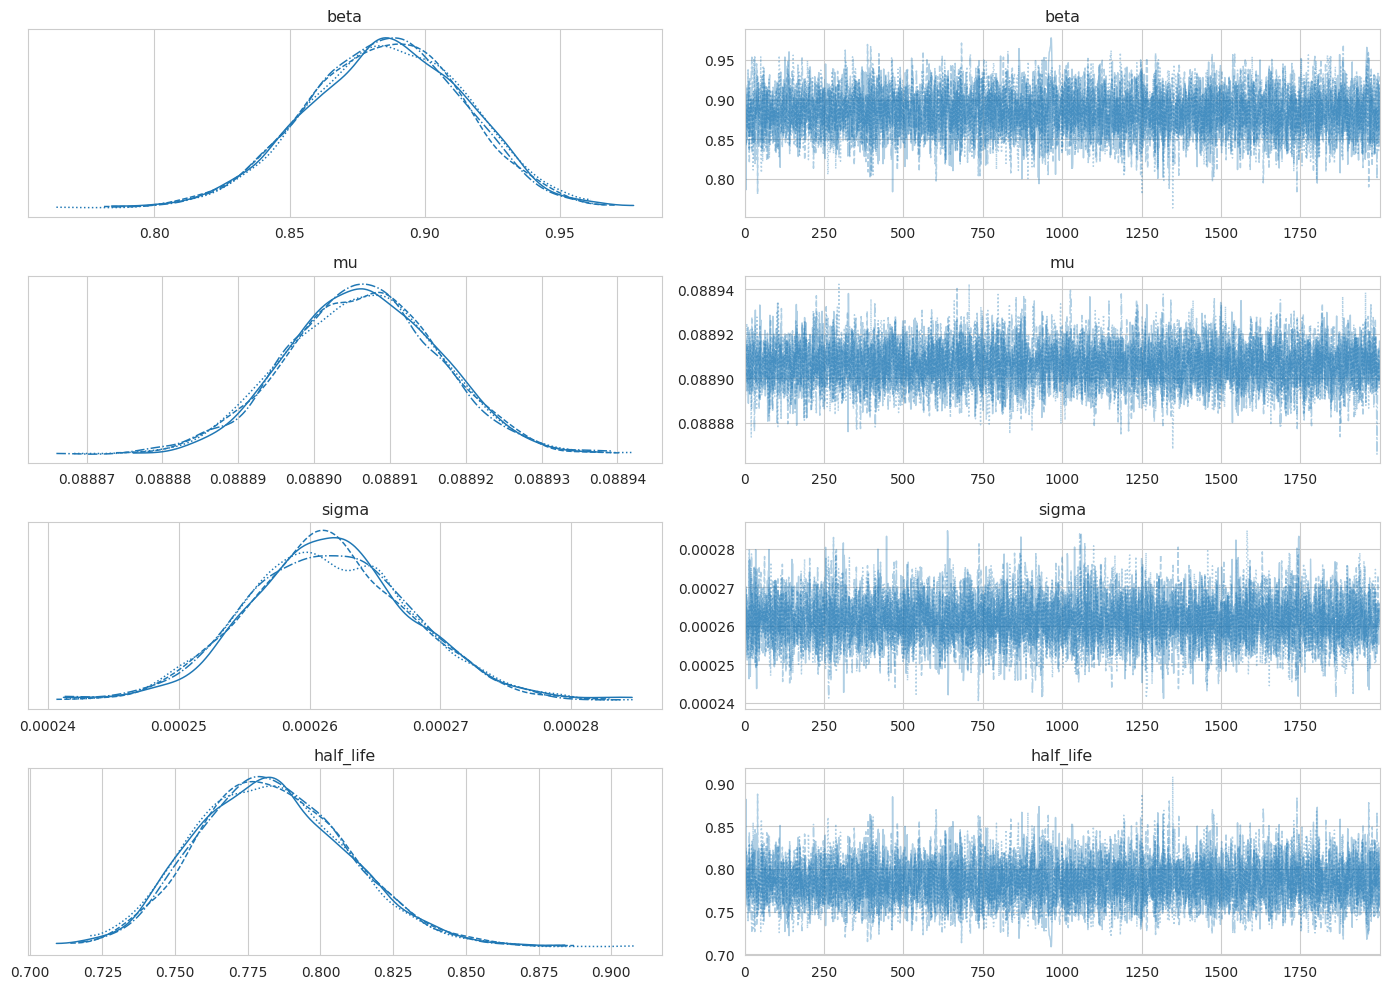


✓ Trace plots saved as '03_mcmc_trace_plots.png'


In [58]:
# Convergence diagnostics using ArviZ
print("\n" + "="*70)
print("CONVERGENCE DIAGNOSTICS")
print("="*70)

# Gelman-Rubin Statistic (R̂)
print("\n1. Potential Scale Reduction Factor (R̂):")
print("   R̂ < 1.01 → Good convergence")
print("   R̂ > 1.05 → Poor convergence (need more samples)")
print("-" * 50)

rhat_values = az.rhat(trace)
print(rhat_values)

# Summary statistics
print("\n" + "="*70)
print("2. POSTERIOR SUMMARY STATISTICS")
print("="*70)
summary = az.summary(trace, var_names=['beta', 'mu', 'sigma', 'half_life'])
print(summary)

# Extract key estimates
beta_mean = trace.posterior['beta'].mean().values
mu_mean = trace.posterior['mu'].mean().values
sigma_mean = trace.posterior['sigma'].mean().values
half_life_mean = trace.posterior['half_life'].mean().values

print(f"\n{'='*70}")
print("KEY FINDINGS")
print(f"{'='*70}")
print(f"Mean-reversion speed (β): {beta_mean:.4f}")
print(f"  → Each day, {beta_mean*100:.1f}% of deviation reverts to mean")
print(f"\nHalf-life: {half_life_mean:.2f} days")
print(f"  → Typical spread reverts 50% in ~{half_life_mean:.0f} days")
print(f"\nLong-term mean (μ): {mu_mean:.6f}")
print(f"Volatility (σ): {sigma_mean:.6f}")

# Trace plots (visual inspection of convergence)
print(f"\n{'='*70}")
print("3. TRACE PLOTS (should look like 'hairy caterpillars')")
print(f"{'='*70}")

fig = az.plot_trace(trace, var_names=['beta', 'mu', 'sigma', 'half_life'],
                    figsize=(14, 10))
plt.tight_layout()
plt.savefig('03_mcmc_trace_plots.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✓ Trace plots saved as '03_mcmc_trace_plots.png'")


POSTERIOR DISTRIBUTIONS


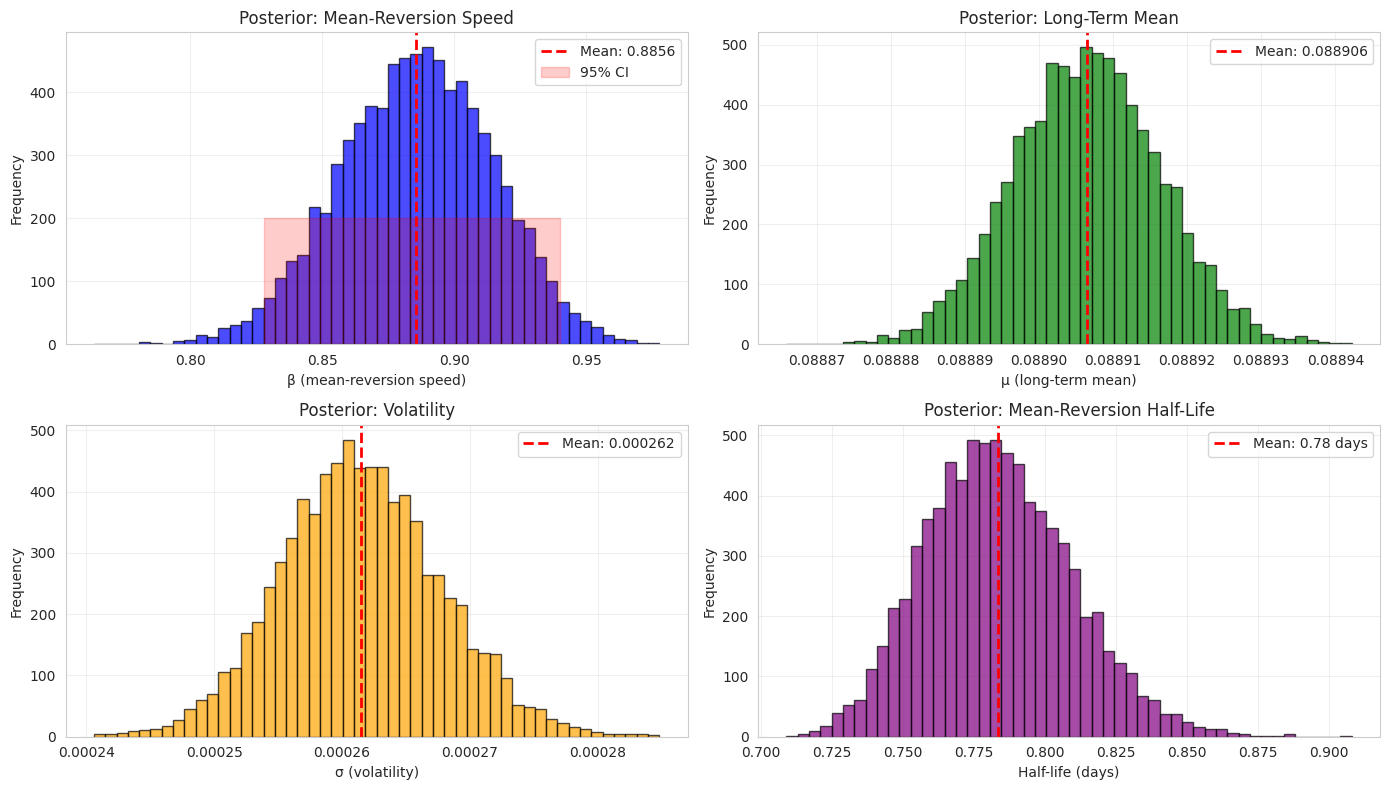

Output()


✓ Posterior plots saved as '04_posterior_distributions.png'

POSTERIOR PREDICTIVE CHECK


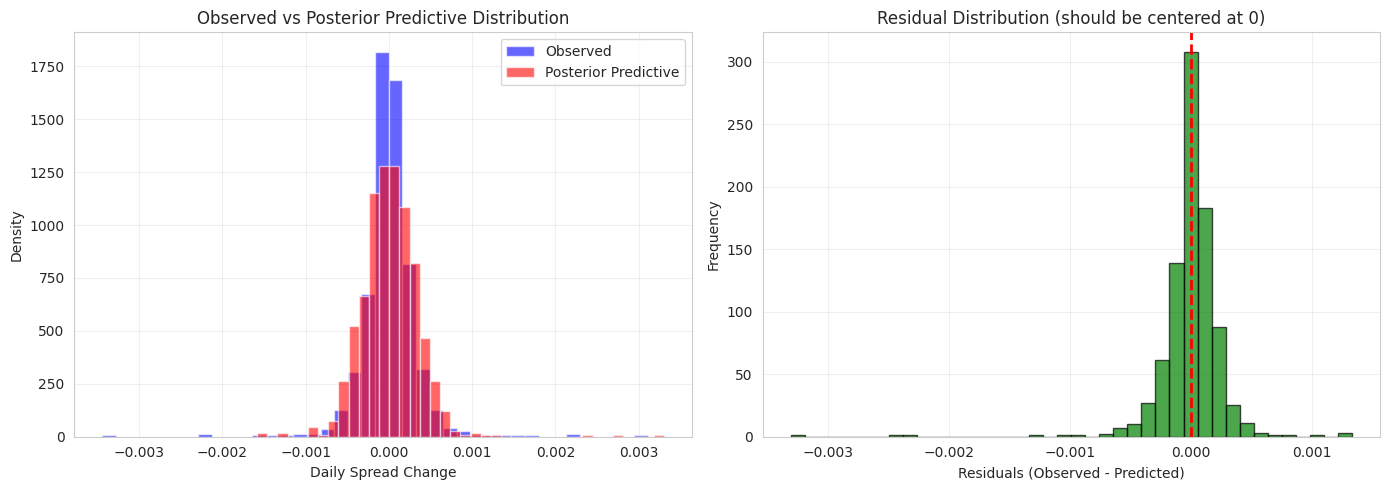

✓ Posterior predictive check complete


In [59]:
# Visualize posterior distributions
print("\n" + "="*70)
print("POSTERIOR DISTRIBUTIONS")
print("="*70)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Extract posteriors
posterior_beta = trace.posterior['beta'].values.flatten()
posterior_mu = trace.posterior['mu'].values.flatten()
posterior_sigma = trace.posterior['sigma'].values.flatten()
posterior_half_life = trace.posterior['half_life'].values.flatten()

# Plot 1: Beta (mean-reversion speed)
axes[0, 0].hist(posterior_beta, bins=50, alpha=0.7, color='blue', edgecolor='black')
axes[0, 0].axvline(posterior_beta.mean(), color='red', linestyle='--', linewidth=2,
                   label=f'Mean: {posterior_beta.mean():.4f}')
axes[0, 0].fill_betweenx([0, 200],
                         np.percentile(posterior_beta, 2.5),
                         np.percentile(posterior_beta, 97.5),
                         alpha=0.2, color='red', label='95% CI')
axes[0, 0].set_xlabel('β (mean-reversion speed)')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Posterior: Mean-Reversion Speed')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Plot 2: Mu (long-term mean)
axes[0, 1].hist(posterior_mu, bins=50, alpha=0.7, color='green', edgecolor='black')
axes[0, 1].axvline(posterior_mu.mean(), color='red', linestyle='--', linewidth=2,
                   label=f'Mean: {posterior_mu.mean():.6f}')
axes[0, 1].set_xlabel('μ (long-term mean)')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('Posterior: Long-Term Mean')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Plot 3: Sigma (volatility)
axes[1, 0].hist(posterior_sigma, bins=50, alpha=0.7, color='orange', edgecolor='black')
axes[1, 0].axvline(posterior_sigma.mean(), color='red', linestyle='--', linewidth=2,
                   label=f'Mean: {posterior_sigma.mean():.6f}')
axes[1, 0].set_xlabel('σ (volatility)')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].set_title('Posterior: Volatility')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Plot 4: Half-life
axes[1, 1].hist(posterior_half_life, bins=50, alpha=0.7, color='purple', edgecolor='black')
axes[1, 1].axvline(posterior_half_life.mean(), color='red', linestyle='--', linewidth=2,
                   label=f'Mean: {posterior_half_life.mean():.2f} days')
axes[1, 1].set_xlabel('Half-life (days)')
axes[1, 1].set_ylabel('Frequency')
axes[1, 1].set_title('Posterior: Mean-Reversion Half-Life')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('04_posterior_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✓ Posterior plots saved as '04_posterior_distributions.png'")

# Posterior predictive check
print(f"\n{'='*70}")
print("POSTERIOR PREDICTIVE CHECK")
print(f"{'='*70}")

with model_ou:
    ppc = pm.sample_posterior_predictive(trace, random_seed=42)

# Plot posterior predictive vs observed data
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Data vs posterior predictive
observed = changes
posterior_pred = ppc.posterior_predictive['obs'].values.flatten()[:len(observed)]

axes[0].hist(observed, bins=40, alpha=0.6, label='Observed', density=True, color='blue')
axes[0].hist(posterior_pred, bins=40, alpha=0.6, label='Posterior Predictive',
            density=True, color='red')
axes[0].set_xlabel('Daily Spread Change')
axes[0].set_ylabel('Density')
axes[0].set_title('Observed vs Posterior Predictive Distribution')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Residuals check
mu_pred = posterior_beta.mean() * (posterior_mu.mean() - lagged_spread)
residuals = changes - mu_pred

axes[1].hist(residuals, bins=40, alpha=0.7, color='green', edgecolor='black')
axes[1].axvline(0, color='red', linestyle='--', linewidth=2)
axes[1].set_xlabel('Residuals (Observed - Predicted)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Residual Distribution (should be centered at 0)')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('05_posterior_predictive_check.png', dpi=150, bbox_inches='tight')
plt.show()

print("✓ Posterior predictive check complete")


TRAIN/TEST SPLIT

Train period: 2023-03-15 to 2025-10-24 (657 days)
Test period: 2025-10-27 to 2026-09-11 (220 days)


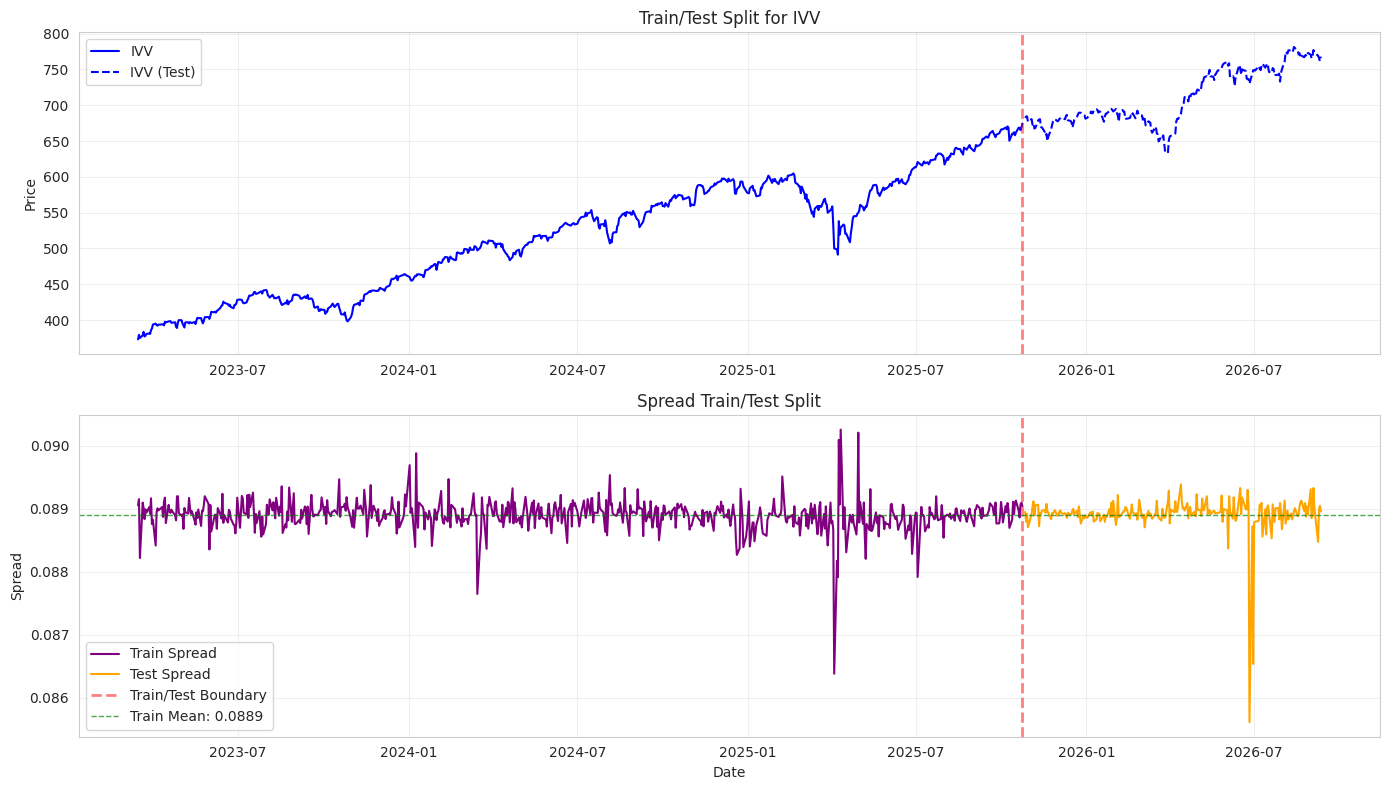


✓ Train/test split visualized


In [60]:
# Split data into train (3 years) and test (1 year)
print("\n" + "="*70)
print("TRAIN/TEST SPLIT")
print("="*70)

total_length = len(spread)
train_length = int(total_length * 0.75)  # ~3 years
test_length = total_length - train_length  # ~1 year

# Train data
train_dates = spread.index[:train_length]
train_prices = selected_data.iloc[:train_length]
train_spread = spread.iloc[:train_length]

# Test data
test_dates = spread.index[train_length:]
test_prices = selected_data.iloc[train_length:]
test_spread = spread.iloc[train_length:]

print(f"\nTrain period: {train_dates[0].date()} to {train_dates[-1].date()} ({len(train_dates)} days)")
print(f"Test period: {test_dates[0].date()} to {test_dates[-1].date()} ({len(test_dates)} days)")

# Plot train/test split
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Prices
axes[0].plot(train_dates, train_prices[stock1], label=stock1, linewidth=1.5, color='blue')
axes[0].plot(test_dates, test_prices[stock1], label=stock1 + ' (Test)', linewidth=1.5,
            color='blue', linestyle='--')
axes[0].axvline(train_dates[-1], color='red', linestyle='--', linewidth=2, alpha=0.5)
axes[0].set_ylabel('Price')
axes[0].set_title(f'Train/Test Split for {stock1}')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Spread
axes[1].plot(train_dates, train_spread.values, label='Train Spread', linewidth=1.5, color='purple')
axes[1].plot(test_dates, test_spread.values, label='Test Spread', linewidth=1.5,
            color='orange')
axes[1].axvline(train_dates[-1], color='red', linestyle='--', linewidth=2, alpha=0.5,
               label='Train/Test Boundary')
axes[1].axhline(train_spread.mean(), color='green', linestyle='--', linewidth=1, alpha=0.7,
               label=f'Train Mean: {train_spread.mean():.4f}')
axes[1].set_ylabel('Spread')
axes[1].set_xlabel('Date')
axes[1].set_title('Spread Train/Test Split')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('06_train_test_split.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✓ Train/test split visualized")


DIAGNOSTIC: SPREAD ANALYSIS IN TEST SET

Test set length: 220 days
Rolling window: 20 days
Valid z-scores: 201 / 220

Spread statistics (test set):
  Mean: 0.088918
  Std: 0.000309
  Min: 0.085612
  Max: 0.089388

Z-score statistics (where valid):
  Mean: 0.0269
  Std: 1.0416
  Min: -4.0936
  Max: 2.8414
  Count > 2: 10
  Count < -2: 6
  Total extremes (|z| > 2): 16


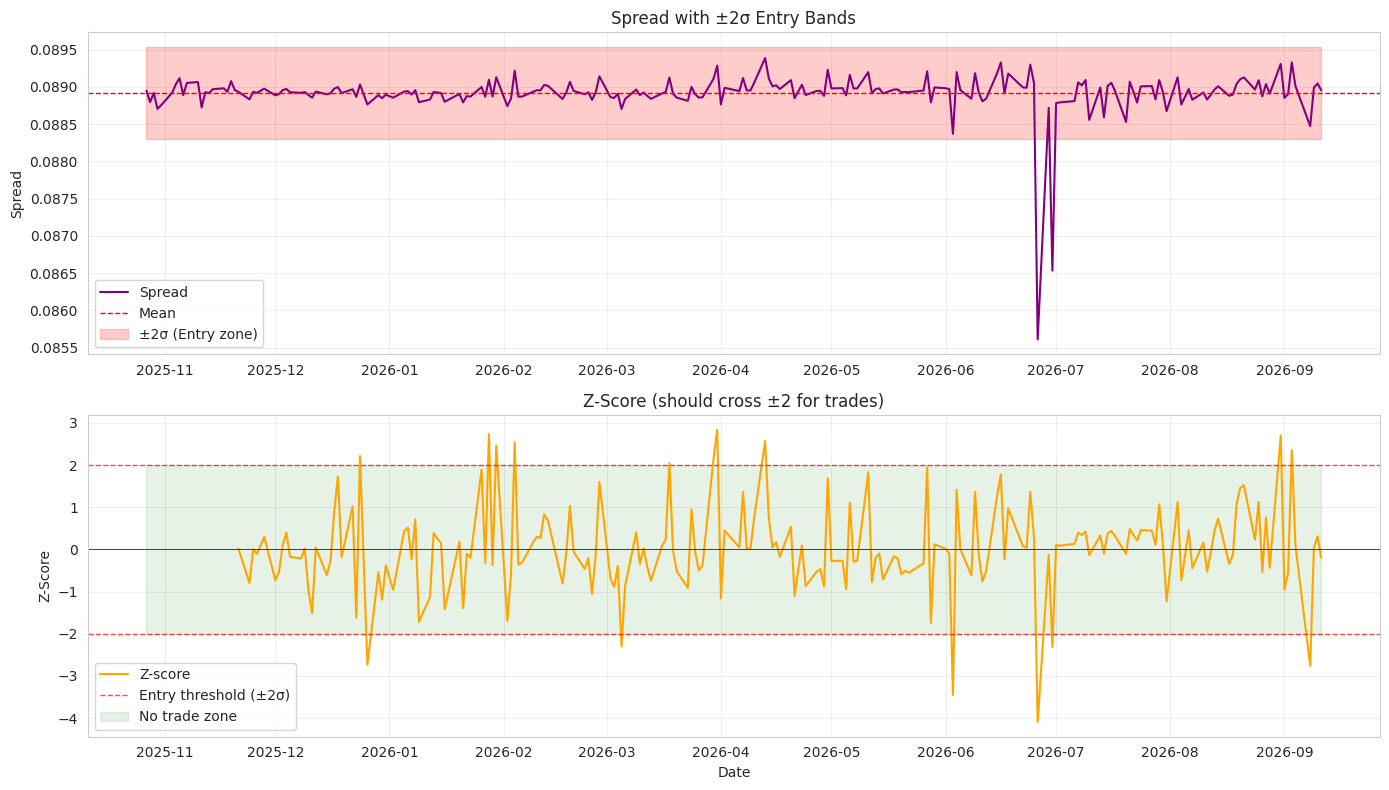


✓ Diagnostic plot saved


In [61]:
# DIAGNOSTIC: Check spread behavior in test set
print("\n" + "="*70)
print("DIAGNOSTIC: SPREAD ANALYSIS IN TEST SET")
print("="*70)

# Calculate rolling stats
window = 20
rolling_mean = test_spread.rolling(window=window).mean()
rolling_std = test_spread.rolling(window=window).std()
z_score = (test_spread - rolling_mean) / rolling_std

print(f"\nTest set length: {len(test_spread)} days")
print(f"Rolling window: {window} days")
print(f"Valid z-scores: {z_score.notna().sum()} / {len(z_score)}")

print(f"\nSpread statistics (test set):")
print(f"  Mean: {test_spread.mean():.6f}")
print(f"  Std: {test_spread.std():.6f}")
print(f"  Min: {test_spread.min():.6f}")
print(f"  Max: {test_spread.max():.6f}")

print(f"\nZ-score statistics (where valid):")
z_valid = z_score.dropna()
if len(z_valid) > 0:
    print(f"  Mean: {z_valid.mean():.4f}")
    print(f"  Std: {z_valid.std():.4f}")
    print(f"  Min: {z_valid.min():.4f}")
    print(f"  Max: {z_valid.max():.4f}")
    print(f"  Count > 2: {(z_valid > 2).sum()}")
    print(f"  Count < -2: {(z_valid < -2).sum()}")
    print(f"  Total extremes (|z| > 2): {((z_valid.abs() > 2).sum())}")
else:
    print("  NO VALID Z-SCORES!")

# Plot spread and z-score
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Spread
axes[0].plot(test_dates, test_spread.values, linewidth=1.5, color='purple', label='Spread')
axes[0].axhline(test_spread.mean(), color='red', linestyle='--', linewidth=1, label='Mean')
axes[0].fill_between(test_dates,
                     test_spread.mean() - 2*test_spread.std(),
                     test_spread.mean() + 2*test_spread.std(),
                     alpha=0.2, color='red', label='±2σ (Entry zone)')
axes[0].set_ylabel('Spread')
axes[0].set_title('Spread with ±2σ Entry Bands')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Z-score
axes[1].plot(test_dates, z_score.values, linewidth=1.5, color='orange', label='Z-score')
axes[1].axhline(0, color='black', linestyle='-', linewidth=0.5)
axes[1].axhline(2, color='red', linestyle='--', linewidth=1, alpha=0.7, label='Entry threshold (±2σ)')
axes[1].axhline(-2, color='red', linestyle='--', linewidth=1, alpha=0.7)
axes[1].fill_between(test_dates, -2, 2, alpha=0.1, color='green', label='No trade zone')
axes[1].set_ylabel('Z-Score')
axes[1].set_xlabel('Date')
axes[1].set_title('Z-Score (should cross ±2 for trades)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('diagnostic_spread_zscore.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✓ Diagnostic plot saved")


MEAN-REVERSION VALIDATION TEST

Mean-Reversion Test (Training Data):
  Correlation(lagged_spread, change): -0.6764

  ✓ STRONG mean-reversion detected
    Spread reverts 67.6% per day


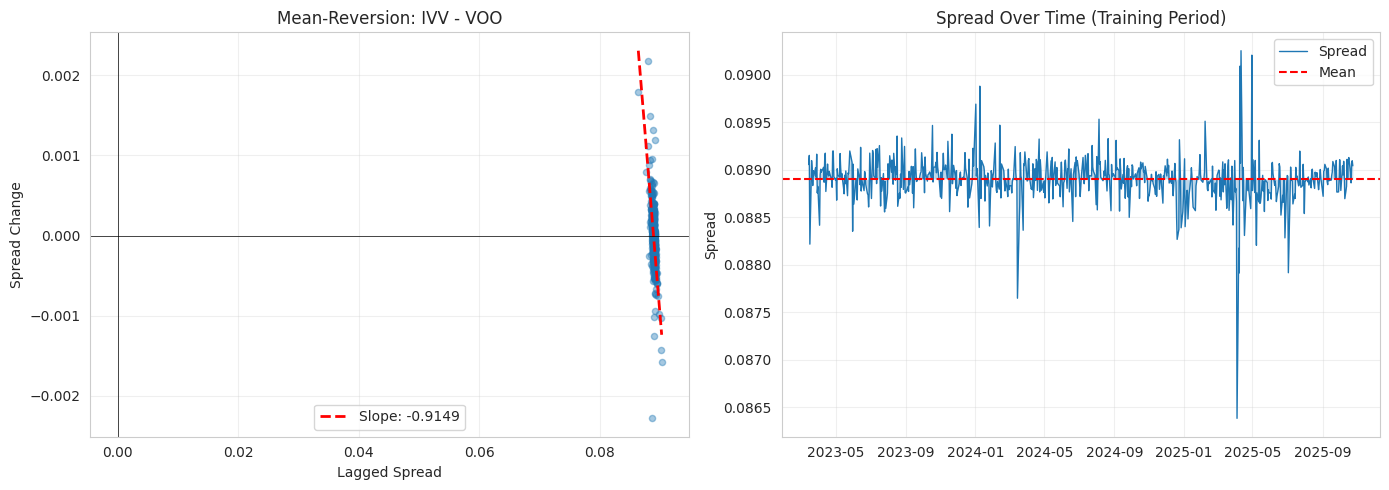


✓ Mean-reversion test plot saved


In [62]:
# TEST: Are the pairs actually mean-reverting?

print("\n" + "="*70)
print("MEAN-REVERSION VALIDATION TEST")
print("="*70)

# Use TRAINING data to check mean-reversion
log_train_prices = np.log(train_prices)
train_spread_series = log_train_prices[stock1] - log_train_prices[stock2]

# Calculate changes
spread_changes = train_spread_series.diff().dropna()
lagged_spread = train_spread_series[:-1].values

# For MEAN-REVERSION, we should see:
# - When spread is positive (too high), next change should be negative (revert down)
# - When spread is negative (too low), next change should be positive (revert up)
# - This means: lagged_spread vs change should have NEGATIVE correlation

correlation = np.corrcoef(lagged_spread, spread_changes.values)[0, 1]

print(f"\nMean-Reversion Test (Training Data):")
print(f"  Correlation(lagged_spread, change): {correlation:.4f}")
print()

if correlation < -0.15:
    print(f"  ✓ STRONG mean-reversion detected")
    print(f"    Spread reverts {abs(correlation)*100:.1f}% per day")
elif correlation < -0.05:
    print(f"  ⚠️  WEAK mean-reversion")
    print(f"    May not be profitable after costs")
else:
    print(f"  ✗ NO MEAN-REVERSION FOUND")
    print(f"    Correlation: {correlation:.4f}")
    print(f"    This pair is NOT suitable for pairs trading!")
    print(f"    → Need to find different pairs")

# Plot it
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter plot
axes[0].scatter(lagged_spread, spread_changes.values, alpha=0.4, s=20)
z = np.polyfit(lagged_spread, spread_changes.values, 1)
p = np.poly1d(z)
x_line = np.linspace(lagged_spread.min(), lagged_spread.max(), 100)
axes[0].plot(x_line, p(x_line), "r--", linewidth=2, label=f'Slope: {z[0]:.4f}')
axes[0].axhline(0, color='black', linestyle='-', linewidth=0.5)
axes[0].axvline(0, color='black', linestyle='-', linewidth=0.5)
axes[0].set_xlabel('Lagged Spread')
axes[0].set_ylabel('Spread Change')
axes[0].set_title(f'Mean-Reversion: {stock1} - {stock2}')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Time series
axes[1].plot(train_spread_series.index, train_spread_series.values, linewidth=1, label='Spread')
axes[1].fill_between(train_spread_series.index, train_spread_series.mean(),
                     train_spread_series.values, alpha=0.3)
axes[1].axhline(train_spread_series.mean(), color='red', linestyle='--', label='Mean')
axes[1].set_ylabel('Spread')
axes[1].set_title(f'Spread Over Time (Training Period)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('mean_reversion_test.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✓ Mean-reversion test plot saved")

In [73]:
# ==============================================================
# CORRECTED PAIRS TRADING BACKTEST
# ==============================================================

import numpy as np
import pandas as pd

print("\n" + "="*70)
print("BACKTESTING PAIRS TRADING STRATEGY")
print("="*70)


def backtest_strategy(
    spread_data,
    prices_data,
    stock1,
    stock2,
    beta,
    entry_threshold=2.0,
    exit_threshold=0.0,
    position_size=100000,
    window=20
):

    """
    Spread:
        S_t = log(P1) - beta * log(P2)

    Trading rules:

        z < -entry_threshold:
            LONG spread
            Long stock1
            Short beta * stock2

        z > +entry_threshold:
            SHORT spread
            Short stock1
            Long beta * stock2

        Exit:
            z >= -exit_threshold for LONG
            z <= +exit_threshold for SHORT

    position_size:
        Total gross capital allocated to the pair.

    Important:
        Daily P&L is calculated as the CHANGE in portfolio
        value from one day to the next, not cumulative trade P&L.
    """

    # ==========================================================
    # 1. ALIGN DATA
    # ==========================================================

    prices_data = prices_data.loc[spread_data.index].copy()

    valid = (
        spread_data.notna()
        & prices_data[stock1].notna()
        & prices_data[stock2].notna()
    )

    spread_data = spread_data.loc[valid]
    prices_data = prices_data.loc[valid]


    # ==========================================================
    # 2. ROLLING Z-SCORE
    # ==========================================================

    # Use only information available before the current day
    rolling_mean = (
        spread_data
        .shift(1)
        .rolling(window=window)
        .mean()
    )

    rolling_std = (
        spread_data
        .shift(1)
        .rolling(window=window)
        .std()
    )

    z_score = (
        (spread_data - rolling_mean)
        / rolling_std
    )


    # ==========================================================
    # 3. INITIALIZE
    # ==========================================================

    trades = []

    position = None

    entry_date = None
    entry_z = None

    entry_price_1 = None
    entry_price_2 = None

    shares_1 = None
    shares_2 = None

    # This stores the portfolio P&L at the previous day
    previous_trade_pnl = 0.0

    # TRUE daily P&L
    daily_pnl = []


    # ==========================================================
    # 4. BACKTEST LOOP
    # ==========================================================

    for i in range(len(spread_data)):

        current_date = spread_data.index[i]

        price1 = float(
            prices_data.iloc[i][stock1]
        )

        price2 = float(
            prices_data.iloc[i][stock2]
        )

        z = z_score.iloc[i]


        # ------------------------------------------------------
        # No valid z-score yet
        # ------------------------------------------------------

        if pd.isna(z):

            daily_pnl.append(0.0)
            continue


        # ======================================================
        # NO POSITION
        # ======================================================

        if position is None:

            # --------------------------------------------------
            # LONG SPREAD
            # --------------------------------------------------
            # z < -2
            #
            # Long stock1
            # Short beta * stock2
            # --------------------------------------------------

            if z < -entry_threshold:

                position = "long"

                entry_date = current_date
                entry_z = float(z)

                entry_price_1 = price1
                entry_price_2 = price2

                # Scale positions so that:
                #
                # shares1 * price1
                # +
                # beta * shares1 * price2
                # =
                # position_size

                shares_1 = (
                    position_size
                    / (
                        price1
                        + abs(beta) * price2
                    )
                )

                shares_2 = (
                    abs(beta) * shares_1
                )

                # No P&L on entry day
                previous_trade_pnl = 0.0

                daily_pnl.append(0.0)


            # --------------------------------------------------
            # SHORT SPREAD
            # --------------------------------------------------
            # z > +2
            #
            # Short stock1
            # Long beta * stock2
            # --------------------------------------------------

            elif z > entry_threshold:

                position = "short"

                entry_date = current_date
                entry_z = float(z)

                entry_price_1 = price1
                entry_price_2 = price2

                shares_1 = (
                    position_size
                    / (
                        price1
                        + abs(beta) * price2
                    )
                )

                shares_2 = (
                    abs(beta) * shares_1
                )

                previous_trade_pnl = 0.0

                daily_pnl.append(0.0)


            else:

                daily_pnl.append(0.0)


        # ======================================================
        # LONG SPREAD
        # ======================================================

        elif position == "long":

            # Current TOTAL trade P&L
            #
            # Long stock1
            # Short stock2

            current_trade_pnl = (
                shares_1
                * (price1 - entry_price_1)
                +
                shares_2
                * (entry_price_2 - price2)
            )

            # TRUE DAILY P&L
            daily_change = (
                current_trade_pnl
                - previous_trade_pnl
            )

            daily_pnl.append(daily_change)

            previous_trade_pnl = current_trade_pnl


            # --------------------------------------------------
            # EXIT
            # --------------------------------------------------

            if z >= exit_threshold:

                trades.append({

                    "entry_date": entry_date,
                    "exit_date": current_date,

                    "position": "LONG",

                    "entry_z": entry_z,
                    "exit_z": float(z),

                    "entry_price_1": entry_price_1,
                    "exit_price_1": price1,

                    "entry_price_2": entry_price_2,
                    "exit_price_2": price2,

                    "shares_1": shares_1,
                    "shares_2": shares_2,

                    "pnl": current_trade_pnl,

                    "duration_days":
                        (current_date - entry_date).days
                })

                position = None

                previous_trade_pnl = 0.0


        # ======================================================
        # SHORT SPREAD
        # ======================================================

        elif position == "short":

            # Current TOTAL trade P&L
            #
            # Short stock1
            # Long stock2

            current_trade_pnl = (
                shares_1
                * (entry_price_1 - price1)
                +
                shares_2
                * (price2 - entry_price_2)
            )

            # TRUE DAILY P&L
            daily_change = (
                current_trade_pnl
                - previous_trade_pnl
            )

            daily_pnl.append(daily_change)

            previous_trade_pnl = current_trade_pnl


            # --------------------------------------------------
            # EXIT
            # --------------------------------------------------

            if z <= -exit_threshold:

                trades.append({

                    "entry_date": entry_date,
                    "exit_date": current_date,

                    "position": "SHORT",

                    "entry_z": entry_z,
                    "exit_z": float(z),

                    "entry_price_1": entry_price_1,
                    "exit_price_1": price1,

                    "entry_price_2": entry_price_2,
                    "exit_price_2": price2,

                    "shares_1": shares_1,
                    "shares_2": shares_2,

                    "pnl": current_trade_pnl,

                    "duration_days":
                        (current_date - entry_date).days
                })

                position = None

                previous_trade_pnl = 0.0


    # ==========================================================
    # 5. CLOSE OPEN POSITION AT END OF TEST PERIOD
    # ==========================================================

    if position is not None:

        final_date = spread_data.index[-1]

        final_price1 = float(
            prices_data.iloc[-1][stock1]
        )

        final_price2 = float(
            prices_data.iloc[-1][stock2]
        )

        final_z = float(
            z_score.iloc[-1]
        )


        if position == "long":

            final_pnl = (
                shares_1
                * (final_price1 - entry_price_1)
                +
                shares_2
                * (entry_price_2 - final_price2)
            )

        else:

            final_pnl = (
                shares_1
                * (entry_price_1 - final_price1)
                +
                shares_2
                * (final_price2 - entry_price_2)
            )


        # If not already accounted for,
        # add only the FINAL day's change
        final_daily_change = (
            final_pnl
            - previous_trade_pnl
        )

        daily_pnl[-1] = (
            daily_pnl[-1]
            + final_daily_change
        )


        trades.append({

            "entry_date": entry_date,
            "exit_date": final_date,

            "position": position.upper(),

            "entry_z": entry_z,
            "exit_z": final_z,

            "entry_price_1": entry_price_1,
            "exit_price_1": final_price1,

            "entry_price_2": entry_price_2,
            "exit_price_2": final_price2,

            "shares_1": shares_1,
            "shares_2": shares_2,

            "pnl": final_pnl,

            "duration_days":
                (final_date - entry_date).days
        })


    # ==========================================================
    # 6. CONVERT P&L TO SERIES
    # ==========================================================

    daily_pnl = pd.Series(
        daily_pnl,
        index=spread_data.index,
        name="daily_pnl"
    )

    # THIS IS NOW A TRUE CUMULATIVE P&L
    cumulative_pnl = daily_pnl.cumsum()

    trades_df = pd.DataFrame(trades)


    # ==========================================================
    # 7. RETURN
    # ==========================================================

    return {

        "trades": trades,

        "trades_df": trades_df,

        "daily_pnl": daily_pnl,

        "cumulative_pnl": cumulative_pnl,

        "z_score": z_score,

        "rolling_mean": rolling_mean,

        "rolling_std": rolling_std
    }



# ==============================================================
# RUN BACKTEST
# ==============================================================

backtest_results = backtest_strategy(

    spread_data=test_spread,

    prices_data=test_prices,

    stock1=stock1,

    stock2=stock2,

    beta=posterior_beta.mean(),

    entry_threshold=2.0,

    exit_threshold=0.0,

    position_size=100000,

    window=20
)


# ==============================================================
# EXTRACT RESULTS
# ==============================================================

trades_df = backtest_results["trades_df"]

daily_pnl = backtest_results["daily_pnl"]

cumulative_pnl = backtest_results["cumulative_pnl"]

z_score = backtest_results["z_score"]


# ==============================================================
# PRINT RESULTS
# ==============================================================

print("\n" + "="*70)
print("BACKTEST RESULTS")
print("="*70)

print(
    f"\nNumber of trades: "
    f"{len(trades_df)}"
)


if len(trades_df) > 0:

    total_pnl = trades_df["pnl"].sum()

    winning = (
        trades_df["pnl"] > 0
    ).sum()

    losing = (
        trades_df["pnl"] <= 0
    ).sum()

    win_rate = (
        winning
        / len(trades_df)
        * 100
    )

    print(
        f"Winning trades:   "
        f"{winning}"
    )

    print(
        f"Losing trades:    "
        f"{losing}"
    )

    print(
        f"Win rate:         "
        f"{win_rate:.2f}%"
    )

    print(
        f"Total P&L:        "
        f"${total_pnl:,.2f}"
    )

    print(
        f"Average P&L:      "
        f"${trades_df['pnl'].mean():,.2f}"
    )

    print(
        f"Best trade:       "
        f"${trades_df['pnl'].max():,.2f}"
    )

    print(
        f"Worst trade:      "
        f"${trades_df['pnl'].min():,.2f}"
    )

    print(
        f"Average duration: "
        f"{trades_df['duration_days'].mean():.2f} days"
    )

else:

    print("\nNo trades generated.")


# ==============================================================
# VERIFY P&L CONSISTENCY
# ==============================================================

print("\n" + "="*70)
print("P&L CONSISTENCY CHECK")
print("="*70)

trade_total = (
    trades_df["pnl"].sum()
    if len(trades_df) > 0
    else 0.0
)

curve_total = cumulative_pnl.iloc[-1]

print(
    f"Sum of trade P&L: "
    f"${trade_total:,.2f}"
)

print(
    f"Final cumulative P&L: "
    f"${curve_total:,.2f}"
)

print(
    f"Difference: "
    f"${trade_total - curve_total:,.6f}"
)


BACKTESTING PAIRS TRADING STRATEGY

BACKTEST RESULTS

Number of trades: 14
Winning trades:   9
Losing trades:    5
Win rate:         64.29%
Total P&L:        $307.11
Average P&L:      $21.94
Best trade:       $413.09
Worst trade:      $-366.15
Average duration: 2.29 days

P&L CONSISTENCY CHECK
Sum of trade P&L: $307.11
Final cumulative P&L: $307.11
Difference: $0.000000


In [74]:
# ==============================================================
# PERFORMANCE METRICS
# ==============================================================

print("\n" + "="*70)
print("PERFORMANCE METRICS")
print("="*70)

if len(trades_df) > 0:

    gross_profit = trades_df.loc[
        trades_df["pnl"] > 0, "pnl"
    ].sum()

    gross_loss = trades_df.loc[
        trades_df["pnl"] < 0, "pnl"
    ].sum()

    profit_factor = (
        gross_profit / abs(gross_loss)
        if gross_loss != 0 else np.inf
    )

    # Daily returns based on $100,000 capital
    daily_returns = daily_pnl / 100000

    sharpe_ratio = (
        daily_returns.mean()
        / daily_returns.std()
        * np.sqrt(252)
        if daily_returns.std() != 0
        else np.nan
    )

    # Equity curve
    equity_curve = 100000 + cumulative_pnl

    running_max = equity_curve.cummax()

    drawdown = equity_curve - running_max

    max_drawdown = drawdown.min()

    max_drawdown_pct = (
        max_drawdown / running_max.max()
        * 100
    )

    print(f"\nGross Profit:       ${gross_profit:,.2f}")
    print(f"Gross Loss:         ${gross_loss:,.2f}")
    print(f"Profit Factor:      {profit_factor:.4f}")
    print(f"Sharpe Ratio:       {sharpe_ratio:.4f}")
    print(f"Max Drawdown:       ${max_drawdown:,.2f}")
    print(f"Max Drawdown (%):   {max_drawdown_pct:.2f}%")

    print("\nInterpretation:")

    if profit_factor > 1:
        print("✓ Profit Factor > 1")
    else:
        print("✗ Profit Factor < 1 → strategy is losing")

    if sharpe_ratio > 1:
        print("✓ Sharpe Ratio > 1")
    else:
        print("✗ Sharpe Ratio < 1")

    print("="*70)


PERFORMANCE METRICS

Gross Profit:       $1,125.22
Gross Loss:         $-818.11
Profit Factor:      1.3754
Sharpe Ratio:       0.5413
Max Drawdown:       $-746.50
Max Drawdown (%):   -0.74%

Interpretation:
✓ Profit Factor > 1
✗ Sharpe Ratio < 1


In [76]:
# ==============================================================
# DIAGNOSTIC: EXAMINE INDIVIDUAL TRADES
# ==============================================================

print("\n" + "="*70)
print("DETAILED TRADE ANALYSIS")
print("="*70)

trades_df = backtest_results["trades_df"]

if len(trades_df) > 0:

    print("\nAll Trades:")

    print(
        trades_df[
            [
                "entry_date",
                "exit_date",
                "position",
                "entry_z",
                "exit_z",
                "pnl",
                "duration_days"
            ]
        ].to_string(index=False)
    )

    print("\n" + "="*70)
    print("TRADE SUMMARY")
    print("="*70)

    # ----------------------------------------------------------
    # Individual trades
    # ----------------------------------------------------------

    for idx, trade in trades_df.iterrows():

        entry_z = trade["entry_z"]
        exit_z = trade["exit_z"]
        pnl = trade["pnl"]
        duration = trade["duration_days"]
        position = trade["position"]

        status = (
            "✓ WIN"
            if pnl > 0
            else "✗ LOSS"
        )

        return_pct = (
            pnl / 100000
        ) * 100

        print(
            f"\nTrade {idx + 1}: "
            f"{position.upper()}"
        )

        print(
            f"  Entry:    "
            f"{pd.Timestamp(trade['entry_date']).date()} "
            f"at z={entry_z:.4f}"
        )

        print(
            f"  Exit:     "
            f"{pd.Timestamp(trade['exit_date']).date()} "
            f"at z={exit_z:.4f}"
        )

        print(
            f"  Duration: "
            f"{duration} days"
        )

        print(
            f"  P&L:      "
            f"${pnl:,.2f}  {status}"
        )

        print(
            f"  Return:   "
            f"{return_pct:.4f}%"
        )

    # ----------------------------------------------------------
    # Summary statistics
    # ----------------------------------------------------------

    winning = (
        trades_df["pnl"] > 0
    ).sum()

    losing = (
        trades_df["pnl"] <= 0
    ).sum()

    total_trades = len(trades_df)

    total_pnl = trades_df["pnl"].sum()

    avg_pnl = trades_df["pnl"].mean()

    win_rate = (
        winning / total_trades * 100
    )

    avg_duration = (
        trades_df["duration_days"].mean()
    )

    # ----------------------------------------------------------
    # Additional statistics
    # ----------------------------------------------------------

    gross_profit = trades_df.loc[
        trades_df["pnl"] > 0,
        "pnl"
    ].sum()

    gross_loss = trades_df.loc[
        trades_df["pnl"] < 0,
        "pnl"
    ].sum()

    profit_factor = (
        gross_profit / abs(gross_loss)
        if gross_loss != 0
        else np.inf
    )

    best_trade = trades_df["pnl"].max()
    worst_trade = trades_df["pnl"].min()

    # ----------------------------------------------------------
    # Final summary
    # ----------------------------------------------------------

    print("\n" + "="*70)
    print("OVERALL SUMMARY")
    print("="*70)

    print(
        f"Total Trades:       {total_trades}"
    )

    print(
        f"Winning:            {winning}"
    )

    print(
        f"Losing:             {losing}"
    )

    print(
        f"Win Rate:           {win_rate:.2f}%"
    )

    print(
        f"Total P&L:          ${total_pnl:,.2f}"
    )

    print(
        f"Avg P&L/trade:      ${avg_pnl:,.2f}"
    )

    print(
        f"Best Trade:         ${best_trade:,.2f}"
    )

    print(
        f"Worst Trade:        ${worst_trade:,.2f}"
    )

    print(
        f"Avg Duration:       {avg_duration:.2f} days"
    )

    print(
        f"Profit Factor:      {profit_factor:.4f}"
    )

else:

    print("\nNo trades to analyze.")


DETAILED TRADE ANALYSIS

All Trades:
entry_date  exit_date position    entry_z    exit_z         pnl  duration_days
2025-12-24 2025-12-26    SHORT   2.729719 -3.737400   13.796770              2
2026-01-28 2026-01-29    SHORT   3.765917 -0.350127   34.238268              1
2026-01-30 2026-02-02    SHORT   3.190649 -1.880103  -35.595486              3
2026-02-04 2026-02-05    SHORT   3.294890 -0.372692  148.932054              1
2026-03-05 2026-03-09     LONG  -2.391013  0.453957  -36.009242              4
2026-03-18 2026-03-19    SHORT   2.444773 -0.104112   40.114902              1
2026-03-30 2026-04-01    SHORT   2.658020 -1.260980 -366.154430              2
2026-04-13 2026-04-17    SHORT   3.377792 -0.153206 -343.529166              4
2026-05-27 2026-05-28    SHORT   2.321616 -1.888709  -36.819184              1
2026-06-03 2026-06-04     LONG  -6.018544  1.446913   86.740819              1
2026-06-16 2026-06-17    SHORT   2.061930 -0.245331  149.530628              1
2026-06-26 202


CREATING BACKTESTING VISUALIZATIONS
Pair: IVV_VOO


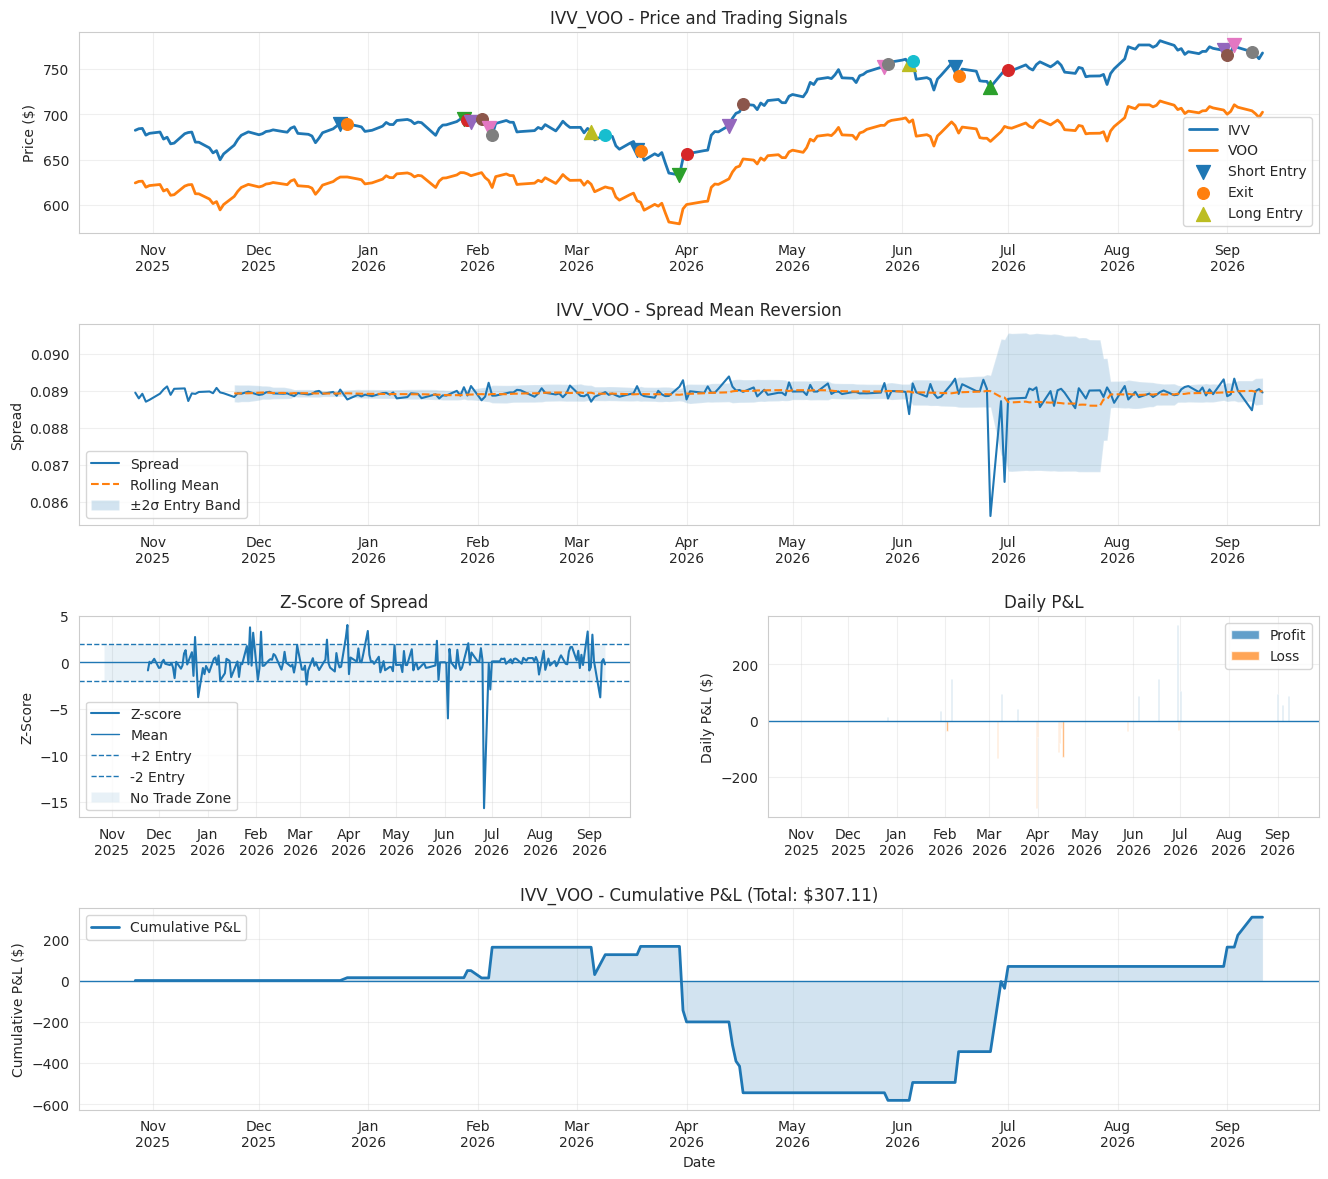


✓ Backtesting visualization saved as '07_backtesting_analysis_IVV_VOO.png'


In [78]:
# ==============================================================
# COMPREHENSIVE BACKTESTING VISUALIZATIONS
# PROPER MEAN-REVERSION STRATEGY
# ==============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

print("\n" + "="*70)
print("CREATING BACKTESTING VISUALIZATIONS")
print("="*70)


# ==============================================================
# 1. GET THE ACTUAL PAIR FROM test_prices
# ==============================================================

stock1 = test_prices.columns[0]
stock2 = test_prices.columns[1]

pair_name = f"{stock1}_{stock2}"

print(f"Pair: {pair_name}")


# ==============================================================
# 2. EXTRACT BACKTEST RESULTS
# ==============================================================

z_score = backtest_results["z_score"].copy()
rolling_mean = backtest_results["rolling_mean"].copy()
rolling_std = backtest_results["rolling_std"].copy()

daily_pnl = backtest_results["daily_pnl"].copy()
cumulative_pnl = backtest_results["cumulative_pnl"].copy()

trades_df = backtest_results["trades_df"].copy()


# ==============================================================
# 3. ALIGN ALL DATA
# ==============================================================

plot_dates = test_spread.index

prices = test_prices.loc[plot_dates]

spread = test_spread.loc[plot_dates]

z_score = z_score.loc[plot_dates]

rolling_mean = rolling_mean.loc[plot_dates]

rolling_std = rolling_std.loc[plot_dates]

daily_pnl = daily_pnl.loc[plot_dates]

cumulative_pnl = cumulative_pnl.loc[plot_dates]


# ==============================================================
# 4. CALCULATE SPREAD BANDS
# ==============================================================

upper_band = rolling_mean + 2 * rolling_std
lower_band = rolling_mean - 2 * rolling_std


# ==============================================================
# 5. CREATE FIGURE
# ==============================================================

fig = plt.figure(figsize=(16, 14))

gs = fig.add_gridspec(
    4,
    2,
    hspace=0.45,
    wspace=0.25
)


# ==============================================================
# 6. COMMON DATE FORMATTER
# ==============================================================

date_locator = mdates.MonthLocator(interval=1)

date_formatter = mdates.DateFormatter(
    "%b\n%Y"
)


# ==============================================================
# 7. PRICE CHART + ENTRY/EXIT SIGNALS
# ==============================================================

ax1 = fig.add_subplot(gs[0, :])

ax1.plot(
    plot_dates,
    prices[stock1],
    label=stock1,
    linewidth=2
)

ax1.plot(
    plot_dates,
    prices[stock2],
    label=stock2,
    linewidth=2
)


# --------------------------------------------------------------
# Plot trade markers
# --------------------------------------------------------------

long_entry_used = False
short_entry_used = False
exit_used = False


for _, trade in trades_df.iterrows():

    entry_date = pd.Timestamp(
        trade["entry_date"]
    )

    exit_date = pd.Timestamp(
        trade["exit_date"]
    )

    position = str(
        trade["position"]
    ).upper()


    # Find closest actual trading date
    entry_idx = (
        np.abs(
            plot_dates.values
            - entry_date.to_datetime64()
        )
    ).argmin()

    exit_idx = (
        np.abs(
            plot_dates.values
            - exit_date.to_datetime64()
        )
    ).argmin()


    # ----------------------------------------------------------
    # LONG ENTRY
    # ----------------------------------------------------------

    if position == "LONG":

        label = (
            "Long Entry"
            if not long_entry_used
            else None
        )

        ax1.scatter(
            plot_dates[entry_idx],
            prices.iloc[entry_idx][stock1],
            marker="^",
            s=100,
            zorder=5,
            label=label
        )

        long_entry_used = True


    # ----------------------------------------------------------
    # SHORT ENTRY
    # ----------------------------------------------------------

    elif position == "SHORT":

        label = (
            "Short Entry"
            if not short_entry_used
            else None
        )

        ax1.scatter(
            plot_dates[entry_idx],
            prices.iloc[entry_idx][stock1],
            marker="v",
            s=100,
            zorder=5,
            label=label
        )

        short_entry_used = True


    # ----------------------------------------------------------
    # EXIT
    # ----------------------------------------------------------

    label = (
        "Exit"
        if not exit_used
        else None
    )

    ax1.scatter(
        plot_dates[exit_idx],
        prices.iloc[exit_idx][stock1],
        marker="o",
        s=70,
        zorder=5,
        label=label
    )

    exit_used = True


ax1.set_title(
    f"{pair_name} - Price and Trading Signals"
)

ax1.set_ylabel(
    "Price ($)"
)

ax1.legend()

ax1.grid(
    True,
    alpha=0.3
)

ax1.xaxis.set_major_locator(
    date_locator
)

ax1.xaxis.set_major_formatter(
    date_formatter
)


# ==============================================================
# 8. SPREAD + ROLLING MEAN + ±2σ
# ==============================================================

ax2 = fig.add_subplot(gs[1, :])


ax2.plot(
    plot_dates,
    spread,
    label="Spread",
    linewidth=1.5
)

ax2.plot(
    plot_dates,
    rolling_mean,
    label="Rolling Mean",
    linestyle="--",
    linewidth=1.5
)


# ±2 standard deviation bands
ax2.fill_between(
    plot_dates,
    lower_band,
    upper_band,
    alpha=0.2,
    label="±2σ Entry Band"
)


# --------------------------------------------------------------
# Mark the rolling mean
# --------------------------------------------------------------

ax2.set_title(
    f"{pair_name} - Spread Mean Reversion"
)

ax2.set_ylabel(
    "Spread"
)

ax2.legend()

ax2.grid(
    True,
    alpha=0.3
)

ax2.xaxis.set_major_locator(
    date_locator
)

ax2.xaxis.set_major_formatter(
    date_formatter
)


# ==============================================================
# 9. Z-SCORE
# ==============================================================

ax3 = fig.add_subplot(gs[2, 0])


ax3.plot(
    plot_dates,
    z_score,
    linewidth=1.5,
    label="Z-score"
)


# Mean
ax3.axhline(
    0,
    linewidth=1,
    label="Mean"
)


# Entry thresholds
ax3.axhline(
    2,
    linestyle="--",
    linewidth=1,
    label="+2 Entry"
)

ax3.axhline(
    -2,
    linestyle="--",
    linewidth=1,
    label="-2 Entry"
)


# No-trade region
ax3.fill_between(
    plot_dates,
    -2,
    2,
    alpha=0.1,
    label="No Trade Zone"
)


ax3.set_title(
    "Z-Score of Spread"
)

ax3.set_ylabel(
    "Z-Score"
)

ax3.legend()

ax3.grid(
    True,
    alpha=0.3
)

ax3.xaxis.set_major_locator(
    date_locator
)

ax3.xaxis.set_major_formatter(
    date_formatter
)


# ==============================================================
# 10. DAILY P&L
# ==============================================================

ax4 = fig.add_subplot(gs[2, 1])


daily_values = daily_pnl.values

positive = daily_values >= 0
negative = daily_values < 0


ax4.bar(
    plot_dates[positive],
    daily_values[positive],
    alpha=0.7,
    label="Profit"
)

ax4.bar(
    plot_dates[negative],
    daily_values[negative],
    alpha=0.7,
    label="Loss"
)


ax4.axhline(
    0,
    linewidth=1
)


ax4.set_title(
    "Daily P&L"
)

ax4.set_ylabel(
    "Daily P&L ($)"
)

ax4.legend()

ax4.grid(
    True,
    alpha=0.3
)

ax4.xaxis.set_major_locator(
    date_locator
)

ax4.xaxis.set_major_formatter(
    date_formatter
)


# ==============================================================
# 11. CUMULATIVE P&L
# ==============================================================

ax5 = fig.add_subplot(gs[3, :])


cumulative_values = cumulative_pnl.values


total_pnl = (
    trades_df["pnl"].sum()
    if len(trades_df) > 0
    else 0.0
)


ax5.plot(
    plot_dates,
    cumulative_values,
    linewidth=2,
    label="Cumulative P&L"
)


ax5.axhline(
    0,
    linewidth=1
)


ax5.fill_between(
    plot_dates,
    0,
    cumulative_values,
    alpha=0.2
)


ax5.set_title(
    f"{pair_name} - Cumulative P&L "
    f"(Total: ${total_pnl:,.2f})"
)

ax5.set_ylabel(
    "Cumulative P&L ($)"
)

ax5.set_xlabel(
    "Date"
)

ax5.legend()

ax5.grid(
    True,
    alpha=0.3
)

ax5.xaxis.set_major_locator(
    date_locator
)

ax5.xaxis.set_major_formatter(
    date_formatter
)


# ==============================================================
# 12. IMPROVE DATE LABELS
# ==============================================================

for ax in [
    ax1,
    ax2,
    ax3,
    ax4,
    ax5
]:

    plt.setp(
        ax.get_xticklabels(),
        rotation=0,
        ha="center"
    )


# ==============================================================
# 13. SAVE
# ==============================================================

filename = (
    f"07_backtesting_analysis_{pair_name}.png"
)

plt.savefig(
    filename,
    dpi=150,
    bbox_inches="tight"
)


# ==============================================================
# 14. DISPLAY
# ==============================================================

plt.show()

print(
    f"\n✓ Backtesting visualization saved as "
    f"'{filename}'"
)